# Detekcija hakerskih napada u CAN mrežama automobila pomoću mašinskog učenja

[HCRL Car-Hacking Dataset](https://ocslab.hksecurity.net/Datasets/car-hacking-dataset)

Detekcija hakerskih napada u CAN mrežama automobila pomoću mašinskog učenja
Elektronski uređaji u automobilu razmjenjuju podatke putem CAN mreže. Tokom snimanja te komunikacije za svaku poruku moguće je zabilježiti vrijeme, identifikator i podatke koje prenosi. U slučaju napada u mrežu se mogu ubaciti dodatne poruke. Tema ovog rada je ispitati kako se takve poruke mogu prepoznati pomoću mašinskog učenja.

U prvom dijelu rada analizirat ću podatke iz skupa HCRL Car-Hacking Dataset. Počet ću od toga kako izgleda jedna zabilježena poruka i šta znači svako njeno polje. Zatim ću provjeriti koliko poruka sadrže odabrane datoteke, koje se vrijednosti ponavljaju i postoje li zapisi koji zahtijevaju dodatnu provjeru. Tako ću upoznati podatke na kojima se zasniva ostatak rada.

Pokretanje. Notebook se pokreće iz foldera koji sadrži podfolder Car-Hacking Dataset. Tabele u tekstu prenio sam iz rada. Kod ispod njih ponavlja izračune iz izvornih datoteka. Za grafikon je potreban matplotlib. Izvor podataka

In [ ]:
import csv
import json
import re
import sqlite3
from collections import Counter
from decimal import Decimal
from itertools import groupby, islice
from pathlib import Path
from tempfile import TemporaryDirectory

projekat = Path.cwd()
folder = projekat / "Car-Hacking Dataset"
datoteke = ["DoS_dataset.csv", "Fuzzy_dataset.csv", "gear_dataset.csv", "RPM_dataset.csv"]

for naziv in datoteke:
    if not (folder / naziv).is_file():
        raise FileNotFoundError(folder / naziv)

## 1. Polazni pregled i struktura skupa podataka

### 1.1. Pregled prvih pet zapisa

Tabela 1. Prikaz pet zapisa iz datoteke DoS.

In [ ]:
datoteka = folder / "DoS_dataset.csv"

with datoteka.open(encoding="utf-8-sig") as ulaz:
    for red in islice(ulaz, 5):
        print(red.rstrip())

print("\nPrvi zapis sa 6 polja:")
with datoteka.open(encoding="utf-8-sig") as ulaz:
    for broj_reda, red in enumerate(ulaz, start=1):
        polja = red.strip().split(",")
        if len(polja) == 6:
            print(f"Red {broj_reda}: {polja}")
            break

### 1.2. Broj zapisa i polja u skupu podataka

Tabela 2. Za svaki zapis provjeravam pravilo **broj polja = DLC + 4**.

In [ ]:
ukupno_zapisa = 0
dlc_po_datoteci = {}

for naziv in datoteke:
    broj_zapisa = 0
    prazni_redovi = 0
    broj_odstupanja = 0
    raspodjela_polja = Counter()
    raspodjela_dlc = Counter()

    with (folder / naziv).open(encoding="utf-8-sig", newline="") as ulaz:
        for red in csv.reader(ulaz):
            if not red:
                prazni_redovi += 1
                continue

            broj_zapisa += 1
            broj_polja = len(red)
            raspodjela_polja[broj_polja] += 1

            try:
                dlc = int(red[2])
            except (IndexError, ValueError):
                broj_odstupanja += 1
                continue

            if not 0 <= dlc <= 8 or broj_polja != dlc + 4:
                broj_odstupanja += 1
            else:
                raspodjela_dlc[dlc] += 1

    dlc_po_datoteci[naziv] = raspodjela_dlc
    ukupno_zapisa += broj_zapisa
    print(f"\n{naziv}")
    print(f"Broj nepraznih zapisa: {broj_zapisa}")
    print(f"Broj praznih redova: {prazni_redovi}")
    for broj_polja, broj_redova in sorted(raspodjela_polja.items()):
        print(f"  Zapisa sa {broj_polja} polja: {broj_redova}")
    print(f"Odstupanja od očekivane dužine prema DLC-u: {broj_odstupanja}")

print(f"\nUkupno zapisa u četiri datoteke: {ukupno_zapisa}")

### 1.3. Jedinstvene vrijednosti i tipovi podataka

Tipove provjeravam na prvom zapisu, a jedinstvene vrijednosti brojim u sve četiri datoteke.

In [ ]:
with (folder / "DoS_dataset.csv").open(encoding="utf-8-sig", newline="") as ulaz:
    prvi_red = next(csv.reader(ulaz))

nazivi = ["Timestamp", "CAN ID", "DLC"]
nazivi.extend(f"DATA[{i}]" for i in range(len(prvi_red[3:-1])))
nazivi.append("Flag")

for naziv, vrijednost in zip(nazivi, prvi_red):
    print(f"{naziv:10} | {vrijednost!r:20} | {type(vrijednost).__name__}")

In [ ]:
nazivi = ["CAN ID", "DLC", *(f"DATA[{i}]" for i in range(8)), "Flag"]
ucestalosti = {naziv: Counter() for naziv in nazivi}
vremena = set()

for naziv_datoteke in datoteke:
    print(f"Čitam {naziv_datoteke}...", flush=True)
    with (folder / naziv_datoteke).open(encoding="utf-8-sig", newline="") as ulaz:
        for red in csv.reader(ulaz):
            if not red:
                continue

            vremena.add(red[0])
            ucestalosti["CAN ID"][red[1]] += 1
            ucestalosti["DLC"][red[2]] += 1
            ucestalosti["Flag"][red[-1]] += 1

            for i, bajt in enumerate(red[3:-1]):
                ucestalosti[f"DATA[{i}]"][bajt] += 1

broj_vremena = len(vremena)
del vremena

print(f"\nUkupno zapisa: {sum(ucestalosti['CAN ID'].values())}")
print(f"Timestamp | različitih vrijednosti: {broj_vremena}")
for naziv, brojac in ucestalosti.items():
    print(f"{naziv} | različitih vrijednosti: {len(brojac)}")

### 1.4. Sažeti pregled varijabli

Tabela 3. Udio vrijednosti bajta računam među porukama koje imaju tu poziciju.

In [ ]:
print(f"{'Varijabla':<12} | {'Tip':<4} | {'Različitih':>11} | Najčešća | Udio (%)")
print(f"{'Timestamp':<12} | {'str':<4} | {broj_vremena:>11} |")
for naziv, brojac in ucestalosti.items():
    if brojac:
        vrijednost, broj_pojava = brojac.most_common(1)[0]
        udio = 100 * broj_pojava / sum(brojac.values())
        print(f"{naziv:<12} | {'str':<4} | {len(brojac):>11} | {vrijednost:>8} | {udio:>7.2f}")
    else:
        print(f"{naziv:<12} | {'str':<4} | {0:>11} |")

### 1.5. Šta predstavlja jedan red i koje se vrijednosti ponavljaju

Jedan red predstavlja CAN poruku. Isti identifikator i ista vremenska oznaka mogu se pojaviti u više redova.

In [ ]:
print("Broj poruka:", ukupno_zapisa)
print("Različitih vremenskih oznaka:", broj_vremena)
print("Različitih CAN ID-eva:", len(ucestalosti["CAN ID"]))
print("Poruke s CAN ID-em 0316:", ucestalosti["CAN ID"]["0316"])

## 2. Nedostajući podaci i početna provjera kvalitete

### 2.1. Nedostajuće vrijednosti po varijabli

Tabela 4. DLC određuje koje pozicije bajtova očekujem. Vrijednost 00 je prisutan bajt.

In [ ]:
bajtovi = [f"DATA[{i}]" for i in range(8)]
varijable = ["Timestamp", "CAN ID", "DLC", *bajtovi, "Flag"]
nedostaje = dict.fromkeys(varijable, 0)
nije_primjenjivo = dict.fromkeys(varijable, 0)
oznake_nedostajanja = {"", "na", "n/a", "nan", "null", "none", "?"}

ukupno = 0
popunjeno_svih_12 = 0
potpuni_prema_dlc = 0

for naziv in datoteke:
    print(f"Čitam {naziv}...", flush=True)
    with (folder / naziv).open(encoding="utf-8-sig", newline="") as ulaz:
        for broj_reda, red in enumerate(csv.reader(ulaz), start=1):
            if not red:
                continue

            dlc = int(red[2])
            if not 0 <= dlc <= 8 or len(red) != dlc + 4:
                raise ValueError(f"Neočekivan raspored: {naziv}, red {broj_reda}")

            ukupno += 1
            nedostaje_u_redu = False
            nazivi_u_redu = ["Timestamp", "CAN ID", "DLC", *bajtovi[:dlc], "Flag"]

            for varijabla, vrijednost in zip(nazivi_u_redu, red):
                if vrijednost.strip().lower() in oznake_nedostajanja:
                    nedostaje[varijabla] += 1
                    nedostaje_u_redu = True

            for varijabla in bajtovi[dlc:]:
                nije_primjenjivo[varijabla] += 1

            if not nedostaje_u_redu:
                potpuni_prema_dlc += 1
                if dlc == 8:
                    popunjeno_svih_12 += 1

print(f"\nUkupno zapisa: {ukupno}")
print("Varijabla | Nedostaje očekivana vrijednost | % svih zapisa | "
      "Nije primjenjivo | % svih zapisa")
for varijabla in varijable:
    broj = nedostaje[varijabla]
    broj_np = nije_primjenjivo[varijabla]
    print(f"{varijabla} | {broj} | {100 * broj / ukupno:.4f}% | "
          f"{broj_np} | {100 * broj_np / ukupno:.4f}%")

### 2.2. Potpuni i nepotpuni zapisi

In [ ]:
print(f"Svih 12 polja popunjeno: {popunjeno_svih_12}")
print(f"Barem jedno od 12 polja bez vrijednosti: {ukupno - popunjeno_svih_12}")
print(f"Sve očekivane vrijednosti prisutne prema DLC-u: {potpuni_prema_dlc}")
print(f"Nedostaje barem jedna očekivana vrijednost: {ukupno - potpuni_prema_dlc}")

### 2.3. Potpuno jednaki zapisi i ponovljeni identifikatori

Tabela 5. Poredim sva polja poruke koristeći privremenu SQLite bazu na disku.

In [ ]:
def procitaj_zapise(putanja, broj_datoteke):
    with putanja.open(encoding="utf-8-sig", newline="") as ulaz:
        for red in csv.reader(ulaz):
            if red:
                # Čuvam polja tačno kako su učitana, uključujući početne nule.
                zapis = json.dumps(red, separators=(",", ":"))
                yield zapis, broj_datoteke


ponavljanja_unutar = [0] * len(datoteke)
ponavljanja_izmedju = 0
broj_razlicitih_zapisa = 0
broj_zapisa_koji_se_ponavljaju = 0
po_jednom_u_svim_datotekama = 0
ukupno_redova = 0
primjer = None

with TemporaryDirectory(dir=projekat) as privremeni_folder:
    baza = sqlite3.connect(Path(privremeni_folder) / "provjera.db")

    try:
        baza.execute("PRAGMA temp_store = FILE")
        baza.execute("CREATE TABLE poruke (zapis TEXT, datoteka INTEGER)")

        for broj, naziv in enumerate(datoteke):
            print(f"Učitavam {naziv}...", flush=True)
            prije = baza.total_changes

            with baza:
                baza.executemany(
                    "INSERT INTO poruke VALUES (?, ?)",
                    procitaj_zapise(folder / naziv, broj),
                )

            ukupno_redova += baza.total_changes - prije

        print("Poredim zapise iz sve četiri datoteke...", flush=True)
        rezultat = baza.execute("""
            SELECT zapis, datoteka, COUNT(*)
            FROM poruke
            GROUP BY zapis, datoteka
            ORDER BY zapis, datoteka
        """)

        for zapis, grupa in groupby(rezultat, key=lambda red: red[0]):
            pojave = [(broj, kolicina) for _, broj, kolicina in grupa]
            broj_razlicitih_zapisa += 1

            for broj, kolicina in pojave:
                ponavljanja_unutar[broj] += kolicina - 1

            ponavljanja_izmedju += len(pojave) - 1
            broj_pojava = sum(kolicina for _, kolicina in pojave)

            if broj_pojava > 1:
                broj_zapisa_koji_se_ponavljaju += 1
                if primjer is None:
                    primjer = (json.loads(zapis), pojave)

            if len(pojave) == broj_pojava == len(datoteke):
                po_jednom_u_svim_datotekama += 1
    finally:
        baza.close()

print("\nPonavljanja unutar pojedinačnih datoteka:")
for naziv, broj in zip(datoteke, ponavljanja_unutar):
    print(f"{naziv}: {broj}")

print(f"\nUkupno pregledanih redova: {ukupno_redova}")
print(f"Različitih potpunih zapisa: {broj_razlicitih_zapisa}")
print(f"Različitih zapisa koji se pojavljuju više puta: {broj_zapisa_koji_se_ponavljaju}")
print(f"Zapisa koji se pojavljuju po jednom u svakoj datoteci: {po_jednom_u_svim_datotekama}")
print(f"Dodatnih pojavljivanja unutar datoteka: {sum(ponavljanja_unutar)}")
print(f"Dodatnih pojavljivanja između datoteka: {ponavljanja_izmedju}")
print(f"Ukupno dodatnih pojavljivanja: {ukupno_redova - broj_razlicitih_zapisa}")

if primjer:
    zapis, pojave = primjer
    print("\nPrimjer potpuno jednakog zapisa:")
    print(",".join(zapis))
    for broj, kolicina in pojave:
        print(f"  {datoteke[broj]}: {kolicina} puta")

### 2.4. Provjera ispravnosti vrijednosti

Tabela 6. Provjeravam format vremena, redoslijed zapisa, CAN ID, bajtove i oznake.

In [ ]:
format_vremena = re.compile(r"[0-9]+(?:\.[0-9]+)?")
format_id = re.compile(r"[0-9a-fA-F]+")
format_bajta = re.compile(r"[0-9a-fA-F]{2}")

for naziv in datoteke:
    print(f"\nProvjeravam {naziv}...", flush=True)

    broj_zapisa = 0
    neispravno_vrijeme = 0
    vrijeme_unazad = 0
    neispravan_id = 0
    broj_bajtova = 0
    neispravni_bajtovi = 0
    neocekivana_oznaka = 0

    prethodno_vrijeme = None
    najmanje_vrijeme = None
    najvece_vrijeme = None
    duzine_id = Counter()
    primjeri = {}

    with (folder / naziv).open(encoding="utf-8-sig", newline="") as ulaz:
        for broj_reda, red in enumerate(csv.reader(ulaz), start=1):
            if not red:
                continue

            broj_zapisa += 1
            vrijeme, can_id = red[0], red[1]
            oznaka = red[-1]

            if format_vremena.fullmatch(vrijeme):
                trenutno = Decimal(vrijeme)

                if prethodno_vrijeme is not None and trenutno < prethodno_vrijeme:
                    vrijeme_unazad += 1
                    primjeri.setdefault(
                        "Vrijeme ide unazad",
                        (broj_reda, f"{prethodno_vrijeme} -> {trenutno}"),
                    )

                prethodno_vrijeme = trenutno
                if najmanje_vrijeme is None or trenutno < najmanje_vrijeme:
                    najmanje_vrijeme = trenutno
                if najvece_vrijeme is None or trenutno > najvece_vrijeme:
                    najvece_vrijeme = trenutno
            else:
                neispravno_vrijeme += 1
                primjeri.setdefault("Format vremena", (broj_reda, vrijeme))
                prethodno_vrijeme = None

            if format_id.fullmatch(can_id):
                duzine_id[len(can_id)] += 1
            else:
                neispravan_id += 1
                primjeri.setdefault("Format CAN ID-a", (broj_reda, can_id))

            for pozicija, bajt in enumerate(red[3:-1]):
                broj_bajtova += 1
                if not format_bajta.fullmatch(bajt):
                    neispravni_bajtovi += 1
                    primjeri.setdefault(
                        "Format bajta", (broj_reda, f"DATA[{pozicija}] = {bajt!r}")
                    )

            if oznaka not in {"R", "T"}:
                neocekivana_oznaka += 1
                primjeri.setdefault("Oznaka poruke", (broj_reda, oznaka))

    print(f"Pregledano zapisa: {broj_zapisa}")
    print(f"Neispravan format vremena: {neispravno_vrijeme}")
    print(f"Vrijeme ide unazad: {vrijeme_unazad}")
    if najmanje_vrijeme is not None:
        print(f"Vremenski raspon snimka (s): {najvece_vrijeme - najmanje_vrijeme}")
    print(f"CAN ID s neheksadecimalnim zapisom: {neispravan_id}")
    print(f"Dužina CAN ID-a (broj znakova: broj zapisa): {dict(duzine_id)}")
    print(f"Pregledano prisutnih bajtova: {broj_bajtova}")
    print(f"Bajtova s neispravnim zapisom: {neispravni_bajtovi}")
    print(f"Oznaka izvan R/T: {neocekivana_oznaka}")

    for provjera, (broj_reda, vrijednost) in primjeri.items():
        print(f"Prvi primjer – {provjera}, red {broj_reda}: {vrijednost}")

### 2.5. Obrazac nepopunjenih polja

Tabela 7. Brojeve poruka po DLC-u preuzimam iz 1.2.

In [ ]:
print("DLC | Broj poruka | Posljednji upisani bajt | Neprimjenjiva polja | Datoteke")
duzine = sorted({dlc for brojac in dlc_po_datoteci.values() for dlc in brojac})
for dlc in duzine:
    broj_poruka = sum(brojac[dlc] for brojac in dlc_po_datoteci.values())
    posljednji = f"DATA[{dlc - 1}]" if dlc else "nema"
    pozicije = ", ".join(bajtovi[dlc:]) or "nema"
    izvori = ", ".join(ime for ime, brojac in dlc_po_datoteci.items() if brojac[dlc])
    print(f"{dlc} | {broj_poruka} | {posljednji} | {pozicije} | {izvori}")

## 3. Razvrstavanje varijabli prema mjernoj ljestvici

### 3.1. Podjela varijabli prema mjernoj ljestvici

**Tabela 8. Razvrstavanje varijabli prema mjernoj ljestvici**

| Varijabla | Vrsta varijable |
|---|---|
| Timestamp | Kvantitativna, kontinuirana |
| CAN ID | Kvalitativna, nominalna |
| DLC | Kvantitativna, diskretna |
| DATA[0] do DATA[7] | Kvantitativne, diskretne na nivou pojedinačnog bajta |
| Flag | Kvalitativna, nominalna |

### 3.2. Obrazloženje klasifikacije

CAN ID je oznaka grupe. DLC broji bajtove. Timestamp mjeri vrijeme, a DATA polja predstavljaju pojedinačne bajtove. Flag razlikuje redovne i ubačene poruke.

### 3.3. Vremenske, tekstualne i identifikacijske varijable

Razmake između poruka mogu izvesti iz Timestamp-a unutar snimka. CAN ID čuvam s početnim nulama i koristim za grupisanje. Flag koristim za brojanje poruka s oznakama R i T.

### 3.4. Poredak kategorija

CAN ID i Flag imaju kategorije bez prirodnog redoslijeda. U skupu nema ordinalnih varijabli.

## 4. Deskriptivna analiza kvalitativnih varijabli

### 4.1. Zastupljenost redovnih i ubačenih poruka

Čitam DoS_dataset.csv...
Čitam Fuzzy_dataset.csv...
Čitam gear_dataset.csv...
Čitam RPM_dataset.csv...

Tabela 9. Zastupljenost redovnih i ubačenih CAN poruka
Oznaka	Broj poruka	Udio
R	14.237.958	85,93 %
T	2.331.517	14,07 %
Ukupno	16.569.475	100,00 %
Broj različitih kategorija: 2


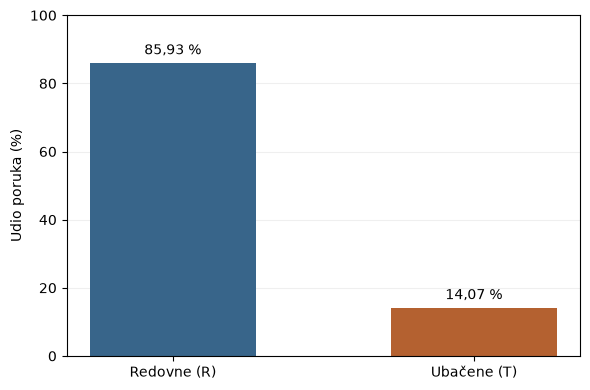

In [31]:
import matplotlib.pyplot as plt

broj_poruka = Counter()
for naziv in datoteke:
    print(f"Čitam {naziv}...", flush=True)
    with (folder / naziv).open(encoding="utf-8-sig", newline="") as ulaz:
        for broj_reda, red in enumerate(csv.reader(ulaz), start=1):
            if not red or red[-1] not in ("R", "T"):
                raise ValueError(f"{naziv}, red {broj_reda}: očekivana je oznaka R ili T.")
            broj_poruka[red[-1]] += 1


def format_broja(broj):
    return f"{broj:,}".replace(",", ".")


def format_procenta(procenat):
    return f"{procenat:.2f}".replace(".", ",") + " %"


ukupno_oznaka = sum(broj_poruka.values())
if ukupno_oznaka != 16_569_475:
    raise ValueError(
        f"Pročitano je {format_broja(ukupno_oznaka)} zapisa, "
        "a u prethodnoj analizi bilo ih je 16.569.475."
    )

oznake = ["R", "T"]
procenti = [100 * broj_poruka[oznaka] / ukupno_oznaka for oznaka in oznake]

print("\nTabela 9. Zastupljenost redovnih i ubačenih CAN poruka")
print("Oznaka\tBroj poruka\tUdio")
for oznaka, procenat in zip(oznake, procenti):
    print(f"{oznaka}\t{format_broja(broj_poruka[oznaka])}\t{format_procenta(procenat)}")
print(f"Ukupno\t{format_broja(ukupno_oznaka)}\t100,00 %")
print(f"Broj različitih kategorija: {len(broj_poruka)}")

fig, ax = plt.subplots(figsize=(6, 4))
stubovi = ax.bar(
    ["Redovne (R)", "Ubačene (T)"],
    procenti,
    color=["#38658A", "#B46130"],
    width=0.55,
)
ax.set_ylabel("Udio poruka (%)")
ax.set_ylim(0, 100)
ax.set_yticks(range(0, 101, 20))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)
ax.bar_label(stubovi, labels=[format_procenta(p) for p in procenti], padding=4)

fig.tight_layout()
fig.savefig(projekat / "grafikon_1_flag.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Grafikon 1. Udio redovnih i ubačenih CAN poruka**

Redovne poruke čine 85,93 % četiri analizirana snimka. Na jednu ubačenu poruku dolazi približno šest redovnih.

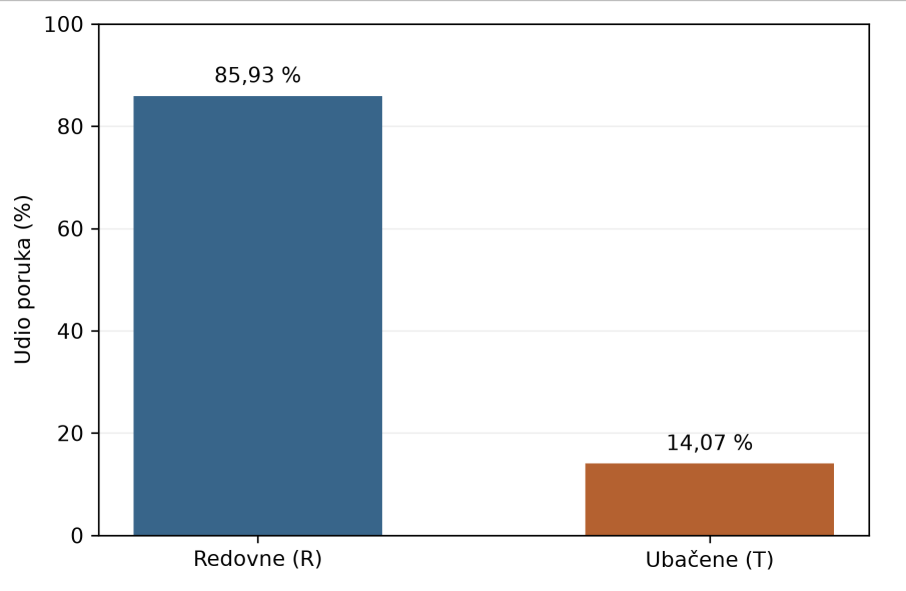

### 4.2. Zastupljenost CAN identifikatora

Koristim broj pojavljivanja svakog CAN ID-a iz dijela 1.3. Izdvajam deset najčešćih identifikatora, računam njihov zajednički udio u svim porukama i provjeravam koji se identifikator pojavljuje najrjeđe.

Ukupan broj poruka: 16.569.475
Broj različitih CAN ID-eva: 2.048

Tabela 10. Deset najčešćih CAN identifikatora
CAN ID	Broj poruka	Udio
0316	1.431.308	8,64 %
043f	1.364.458	8,23 %
018f	776.150	4,68 %
0002	773.822	4,67 %
0153	770.198	4,65 %
0260	769.839	4,65 %
02c0	768.927	4,64 %
0130	767.425	4,63 %
0370	766.585	4,63 %
02a0	765.888	4,62 %
Zajedno	8.954.600	54,04 %

Najmanji broj poruka za jedan CAN ID: 195
CAN ID s tom učestalošću: 0618


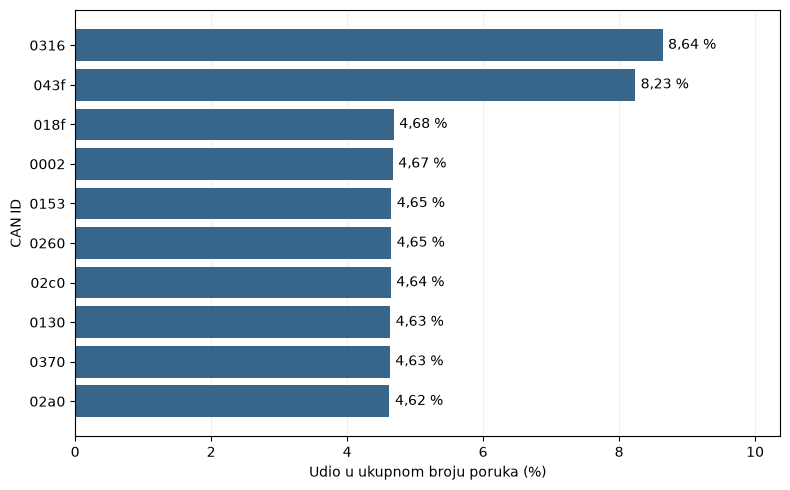

In [30]:
import matplotlib.pyplot as plt

broj_po_id = ucestalosti["CAN ID"]
ukupno_poruka = sum(broj_po_id.values())

# Kod jednakog broja poruka identifikatore poredam po oznaci.
poredani_id = sorted(broj_po_id.items(), key=lambda par: (-par[1], par[0]))
prvih_deset = poredani_id[:10]
zbir_prvih_deset = sum(broj for _, broj in prvih_deset)


def prikazi_broj(broj):
    return f"{broj:,}".replace(",", ".")


def prikazi_udio(broj):
    return f"{100 * broj / ukupno_poruka:.2f}".replace(".", ",") + " %"


print(f"Ukupan broj poruka: {prikazi_broj(ukupno_poruka)}")
print(f"Broj različitih CAN ID-eva: {prikazi_broj(len(broj_po_id))}")

print("\nTabela 10. Deset najčešćih CAN identifikatora")
print("CAN ID\tBroj poruka\tUdio")
for can_id, broj in prvih_deset:
    print(f"{can_id}\t{prikazi_broj(broj)}\t{prikazi_udio(broj)}")

print(f"Zajedno\t{prikazi_broj(zbir_prvih_deset)}\t{prikazi_udio(zbir_prvih_deset)}")

najmanji_broj = poredani_id[-1][1]
najrjedi_id = [can_id for can_id, broj in poredani_id if broj == najmanji_broj]
print(f"\nNajmanji broj poruka za jedan CAN ID: {prikazi_broj(najmanji_broj)}")
print("CAN ID s tom učestalošću:", ", ".join(najrjedi_id))

identifikatori = [can_id for can_id, _ in prvih_deset]
procenti = [100 * broj / ukupno_poruka for _, broj in prvih_deset]
oznake = [prikazi_udio(broj) for _, broj in prvih_deset]

fig, ax = plt.subplots(figsize=(8, 5))
stubovi = ax.barh(identifikatori, procenti, color="#38658A")
ax.invert_yaxis()
ax.set_xlabel("Udio u ukupnom broju poruka (%)")
ax.set_ylabel("CAN ID")
ax.set_xlim(0, max(procenti) * 1.2)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
ax.bar_label(stubovi, labels=oznake, padding=4)

fig.tight_layout()
plt.show()
plt.close(fig)

**Grafikon 2. Udio deset najčešćih CAN identifikatora u ukupnom broju poruka**

Deset najčešćih identifikatora zajedno obuhvata 54,04 % svih poruka. Na grafikonu se izdvajaju 0316 i 043f, dok se udjeli ostalih osam kreću od 4,62 % do 4,68 %. U potpunoj raspodjeli pronašao sam i identifikator 0618, koji se pojavljuje samo 195 puta.

### 4.3. Odnos između CAN identifikatora i oznake poruke

Za deset najčešćih CAN identifikatora prikazujem broj redovnih i ubačenih poruka. Procente računam unutar svakog reda. Koristim potpunu tabelu koju sam dobio skriptom `can_id_flag.py`, a preostale identifikatore za ovaj prikaz objedinjujem u red „Ostali“.

In [29]:
import csv
from pathlib import Path

putanja = Path("kontingencija_can_id_flag.csv")

with putanja.open(encoding="utf-8-sig", newline="") as ulaz:
    redovi = list(csv.DictReader(ulaz, delimiter=";"))

# Skripta je sačuvala identifikatore poredane prema ukupnom broju poruka.
def ispisi_red(naziv, broj_r, broj_t):
    ukupno = broj_r + broj_t
    brojevi = [f"{n:,}".replace(",", ".") for n in (broj_r, broj_t, ukupno)]
    procenti = [f"{100 * n / ukupno:.2f}".replace(".", ",") for n in (broj_r, broj_t)]
    print("\t".join([naziv, *brojevi, *procenti]))


print("Tabela 11. Redovne i ubačene poruke prema CAN identifikatoru")
print("CAN ID\tBroj R\tBroj T\tUkupno\tR (%)\tT (%)")

for red in redovi[:10]:
    ispisi_red(red["CAN ID"], int(red["Broj R"]), int(red["Broj T"]))

ostali_r = sum(int(red["Broj R"]) for red in redovi[10:])
ostali_t = sum(int(red["Broj T"]) for red in redovi[10:])
ispisi_red("Ostali", ostali_r, ostali_t)

ukupno_r = sum(int(red["Broj R"]) for red in redovi)
ukupno_t = sum(int(red["Broj T"]) for red in redovi)
ispisi_red("Ukupno", ukupno_r, ukupno_t)

Tabela 11. Redovne i ubačene poruke prema CAN identifikatoru
CAN ID	Broj R	Broj T	Ukupno	R (%)	T (%)
0316	776.188	655.120	1.431.308	54,23	45,77
043f	766.956	597.502	1.364.458	56,21	43,79
018f	775.884	266	776.150	99,97	0,03
0002	773.581	241	773.822	99,97	0,03
0153	769.923	275	770.198	99,96	0,04
0260	769.590	249	769.839	99,97	0,03
02c0	768.673	254	768.927	99,97	0,03
0130	767.206	219	767.425	99,97	0,03
0370	766.315	270	766.585	99,96	0,04
02a0	765.638	250	765.888	99,97	0,03
Ostali	6.538.004	1.076.871	7.614.875	85,86	14,14
Ukupno	14.237.958	2.331.517	16.569.475	85,93	14,07


U Tabeli 11 uočio sam da oznaku T ima 45,77 % poruka s identifikatorom 0316 i 43,79 % poruka s identifikatorom 043f. Kod ostalih osam pojedinačno prikazanih identifikatora taj udio je između 0,03 % i 0,04 %. Kada posmatram samo ubačene poruke iz sve četiri datoteke, više od polovine njih (53,73 %) ima identifikator 0316 ili 043f.

### 4.4. Poređenje odnosa CAN ID-a i oznake poruke po datotekama

Za identifikatore 0316 i 043f upoređujem udio ubačenih poruka u svakom od četiri snimka. Svaki red Tabele 12 odnosi se na jedan identifikator u jednom snimku. Koristim rezultate skripte `can_id_flag_po_datoteci.py`.

**Tabela 12. Udio ubačenih poruka po identifikatoru i snimku**

| Snimak | CAN ID | Broj R | Broj T | Ukupno poruka | T (%) |
|---|---|---:|---:|---:|---:|
| DoS | `0316` | 166.631 | 0 | 166.631 | 0,00 |
| DoS | `043f` | 166.103 | 0 | 166.103 | 0,00 |
| Fuzzy | `0316` | 181.898 | 223 | 182.121 | 0,12 |
| Fuzzy | `043f` | 179.288 | 250 | 179.538 | 0,14 |
| Gear | `0316` | 211.325 | 0 | 211.325 | 0,00 |
| Gear | `043f` | 207.289 | 597.252 | 804.541 | 74,24 |
| RPM | `0316` | 216.334 | 654.897 | 871.231 | 75,17 |
| RPM | `043f` | 214.276 | 0 | 214.276 | 0,00 |

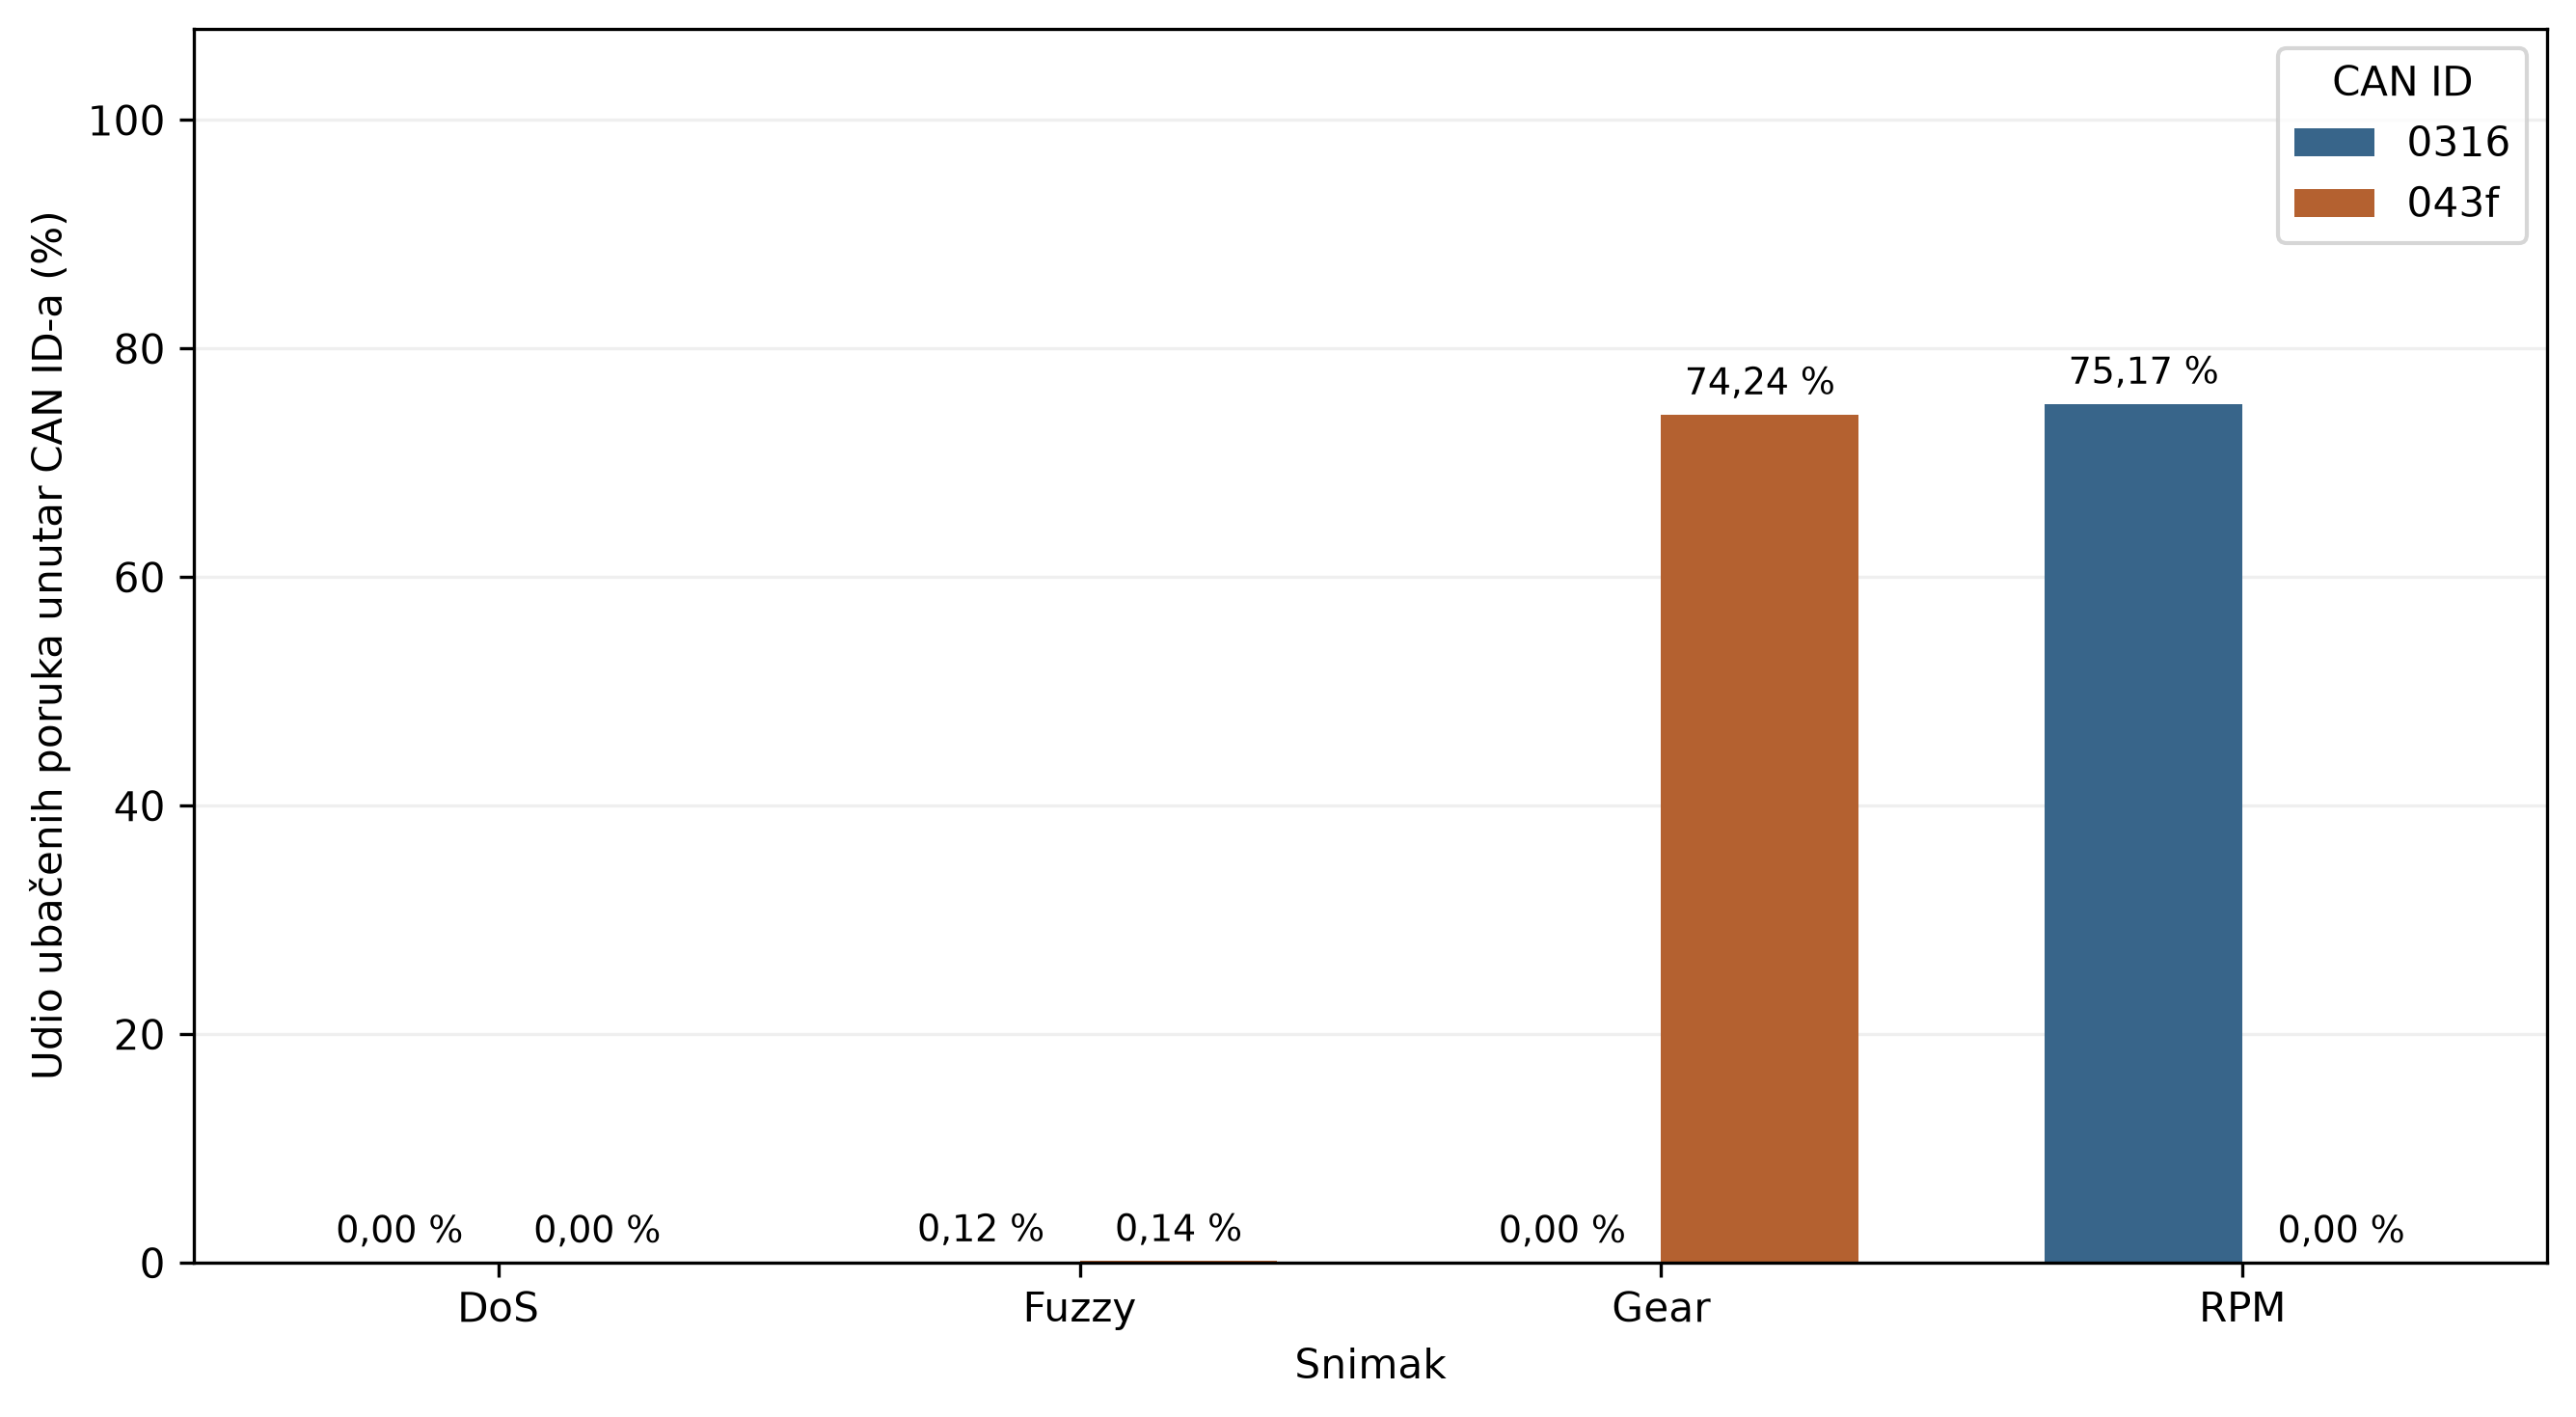

In [28]:
import csv
from pathlib import Path
from IPython.display import Image, Markdown, display

projekat = Path.cwd()
putanja_tabele = projekat / "can_id_flag_po_datoteci.csv"
putanja_grafa = projekat / "grafikon_3_can_id_po_datoteci.png"

with putanja_tabele.open(encoding="utf-8-sig", newline="") as ulaz:
    redovi = list(csv.DictReader(ulaz, delimiter=";"))

def prikazi_broj(vrijednost):
    return f"{int(vrijednost):,}".replace(",", ".")

tabela = [
    "| Snimak | CAN ID | Broj R | Broj T | Ukupno poruka | T (%) |",
    "|---|---|---:|---:|---:|---:|",
]

for red in redovi:
    tabela.append(
        f"| {red['Snimak']} | `{red['CAN ID']}` | "
        f"{prikazi_broj(red['Broj R'])} | {prikazi_broj(red['Broj T'])} | "
        f"{prikazi_broj(red['Ukupno'])} | {red['T (%)']} |"
    )

display(Markdown("**Tabela 12. Udio ubačenih poruka po identifikatoru i snimku**"))
display(Markdown("\n".join(tabela)))
display(Image(filename=str(putanja_grafa), width=760))

**Grafikon 3. Udio ubačenih poruka za identifikatore 0316 i 043f po snimku**

U Gear snimku oznaku T ima 74,24 % poruka s identifikatorom 043f, a u RPM snimku 75,17 % poruka s identifikatorom 0316. U DoS snimku sve poruke s ova dva identifikatora imaju oznaku R. U Fuzzy snimku pronašao sam ubačene poruke za oba identifikatora, s udjelima manjim od 0,15 %. Razdvajanjem po datotekama vidio sam u kojem se snimku svaki od dva identifikatora izdvaja.

## 5. Deskriptivna analiza numeričkih varijabli

### 5.1. Dužina CAN poruke (DLC)

Koristim broj poruka za svaku dužinu iz Tabele 7. Iz tih frekvencija računam pokazatelje za sve poruke i upoređujem aritmetičku sredinu, medijan i skraćenu sredinu.

In [27]:
from math import ceil, sqrt

# Broj poruka za svaku dužinu iz Tabele 7.
broj_po_dlc = {
    2: 147_211,
    5: 53_451,
    6: 3,
    8: 16_368_810,
}

duzine = sorted(broj_po_dlc)
n = sum(broj_po_dlc.values())
sredina = sum(dlc * broj_po_dlc[dlc] for dlc in duzine) / n


def centralni_moment(red):
    return sum(
        broj_po_dlc[dlc] * (dlc - sredina) ** red
        for dlc in duzine
    ) / n


def kvartil(udio):
    # Tražim prvu dužinu na kojoj zbir frekvencija dostigne traženi rang.
    rang = ceil(udio * n)
    do_sada = 0
    for dlc in duzine:
        do_sada += broj_po_dlc[dlc]
        if do_sada >= rang:
            return dlc


# Skraćena sredina računa se na srednjih 90 % sortiranih opažanja.
odbaceno_po_kraju = n // 20
pocetak = odbaceno_po_kraju
kraj = n - odbaceno_po_kraju
pocetak_grupe = 0
zbir_zadrzanih = 0

for dlc in duzine:
    kraj_grupe = pocetak_grupe + broj_po_dlc[dlc]
    broj_zadrzanih = max(0, min(kraj_grupe, kraj) - max(pocetak_grupe, pocetak))
    zbir_zadrzanih += dlc * broj_zadrzanih
    pocetak_grupe = kraj_grupe

skracena_sredina = zbir_zadrzanih / (kraj - pocetak)
standardna_devijacija = sqrt(centralni_moment(2))
koeficijent_varijacije = 100 * standardna_devijacija / sredina
asimetricnost = centralni_moment(3) / standardna_devijacija ** 3
eksces = centralni_moment(4) / standardna_devijacija ** 4 - 3

q1 = kvartil(0.25)
medijan = kvartil(0.50)
q3 = kvartil(0.75)

print("Tabela 13. Deskriptivni pokazatelji za DLC")
print("Broj valjanih opažanja:", f"{n:,}".replace(",", "."))
print("Minimum:", duzine[0])
print("Q1:", q1)
print("Medijan:", medijan)
print("Q3:", q3)
print("Maksimum:", duzine[-1])
print("IQR:", q3 - q1)
print(f"Aritmetička sredina: {sredina:.3f}")
print(f"Skraćena sredina (5 % sa svakog kraja): {skracena_sredina:.3f}")
print(f"Standardna devijacija: {standardna_devijacija:.3f}")
print(f"Koeficijent varijacije: {koeficijent_varijacije:.2f} %")
print(f"Asimetričnost: {asimetricnost:.2f}")
print(f"Zaobljenost (eksces): {eksces:.2f}")

Tabela 13. Deskriptivni pokazatelji za DLC
Broj valjanih opažanja: 16.569.475
Minimum: 2
Q1: 8
Medijan: 8
Q3: 8
Maksimum: 8
IQR: 0
Aritmetička sredina: 7.937
Skraćena sredina (5 % sa svakog kraja): 8.000
Standardna devijacija: 0.587
Koeficijent varijacije: 7.40 %
Asimetričnost: -9.58
Zaobljenost (eksces): 91.81


U Tabeli 13 dobio sam prosječnu dužinu od 7,937 bajtova. Oba kvartila, medijan i skraćena sredina iznose 8 bajtova jer tu dužinu ima 98,79 % svih poruka. Kraće poruke spuštaju prosjek i objašnjavaju zašto je raspodjela izrazito asimetrična prema manjim vrijednostima.

### 5.2. Deskriptivna analiza bajtova sadržaja poruke

Za svaku poziciju od DATA[0] do DATA[7] posmatram samo prisutne bajtove. Vrijednost `00` računam kao nulu. Koristim rezultate skripte `deskriptivna_bajtovi.py` da uporedim kvartile, sredine i raspršenost vrijednosti na osam pozicija.

In [26]:
import csv
from pathlib import Path
from IPython.display import Markdown, display

putanja = Path("deskriptivna_bajtovi.csv")

with putanja.open(encoding="utf-8-sig", newline="") as ulaz:
    rezultati = list(csv.DictReader(ulaz, delimiter=";"))


def prikazi_tabelu(naslov, kolone):
    linije = [
        "| " + " | ".join(kolone) + " |",
        "| " + " | ".join(["---"] + ["---:"] * (len(kolone) - 1)) + " |",
    ]

    for red in rezultati:
        vrijednosti = [red[kolona] for kolona in kolone]
        linije.append("| " + " | ".join(vrijednosti) + " |")

    display(Markdown(f"**{naslov}**\n\n" + "\n".join(linije)))


for red in rezultati:
    red["N"] = f"{int(red['N']):,}".replace(",", ".")

prikazi_tabelu(
    "Tabela 14. Broj opažanja, raspon i kvartili po poziciji bajta",
    ["Varijabla", "N", "Min", "Q1", "Medijan", "Q3", "Maks", "IQR"],
)

prikazi_tabelu(
    "Tabela 15. Sredine, raspršenost i oblik raspodjele po poziciji bajta",
    ["Varijabla", "Sredina", "Skraćena sredina", "SD", "CV (%)",
     "Asimetričnost", "Eksces"],
)

**Tabela 14. Broj opažanja, raspon i kvartili po poziciji bajta**

| Varijabla | N | Min | Q1 | Medijan | Q3 | Maks | IQR |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| DATA[0] | 16.569.475 | 0 | 0 | 8,00 | 69 | 255 | 69 |
| DATA[1] | 16.569.475 | 0 | 0 | 32,00 | 69 | 255 | 69 |
| DATA[2] | 16.422.264 | 0 | 0 | 0,00 | 96 | 255 | 96 |
| DATA[3] | 16.422.264 | 0 | 0 | 20,00 | 137 | 255 | 137 |
| DATA[4] | 16.422.264 | 0 | 0 | 17,00 | 107 | 255 | 107 |
| DATA[5] | 16.368.813 | 0 | 0 | 32,00 | 127 | 255 | 127 |
| DATA[6] | 16.368.810 | 0 | 0 | 0,00 | 10 | 255 | 10 |
| DATA[7] | 16.368.810 | 0 | 0 | 0,00 | 109 | 255 | 109 |

**Tabela 15. Sredine, raspršenost i oblik raspodjele po poziciji bajta**

| Varijabla | Sredina | Skraćena sredina | SD | CV (%) | Asimetričnost | Eksces |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| DATA[0] | 58,04 | 50,33 | 89,86 | 154,82 | 1,40 | 0,27 |
| DATA[1] | 45,53 | 39,91 | 54,46 | 119,62 | 1,30 | 0,90 |
| DATA[2] | 40,39 | 34,32 | 58,51 | 144,86 | 1,34 | 0,79 |
| DATA[3] | 78,47 | 73,03 | 102,33 | 130,40 | 0,92 | -0,87 |
| DATA[4] | 51,74 | 43,33 | 73,35 | 141,75 | 1,51 | 1,32 |
| DATA[5] | 61,89 | 54,62 | 77,34 | 124,95 | 1,12 | 0,06 |
| DATA[6] | 26,33 | 17,95 | 57,42 | 218,10 | 2,32 | 4,00 |
| DATA[7] | 54,20 | 46,10 | 80,21 | 147,99 | 1,33 | 0,40 |

U Tabeli 14 uočio sam da DATA[6] i DATA[7] imaju isti medijan (0), ali različite treće kvartile (10 i 109). Najširi interkvartilni raspon ima DATA[3] (137), koji u Tabeli 15 ima i najveću standardnu devijaciju (102,33).

Kod DATA[6] najmanje 75 % prisutnih vrijednosti iznosi 10 ili manje. Ipak, aritmetička sredina iznosi 26,33, a nakon izostavljanja po 5 % vrijednosti sa svakog kraja pada na 17,95. Na toj poziciji veće vrijednosti najizraženije povlače raspodjelu udesno.

### 5.3. Grafički prikaz raspodjele vrijednosti bajtova

Upoređujem DATA[3] i DATA[6] jer imaju najširi i najuži interkvartilni raspon u Tabeli 14. Svaki stubac obuhvata osam uzastopnih vrijednosti. Narandžasta linija prikazuje normalnu krivu sa sredinom i standardnom devijacijom odgovarajuće pozicije.

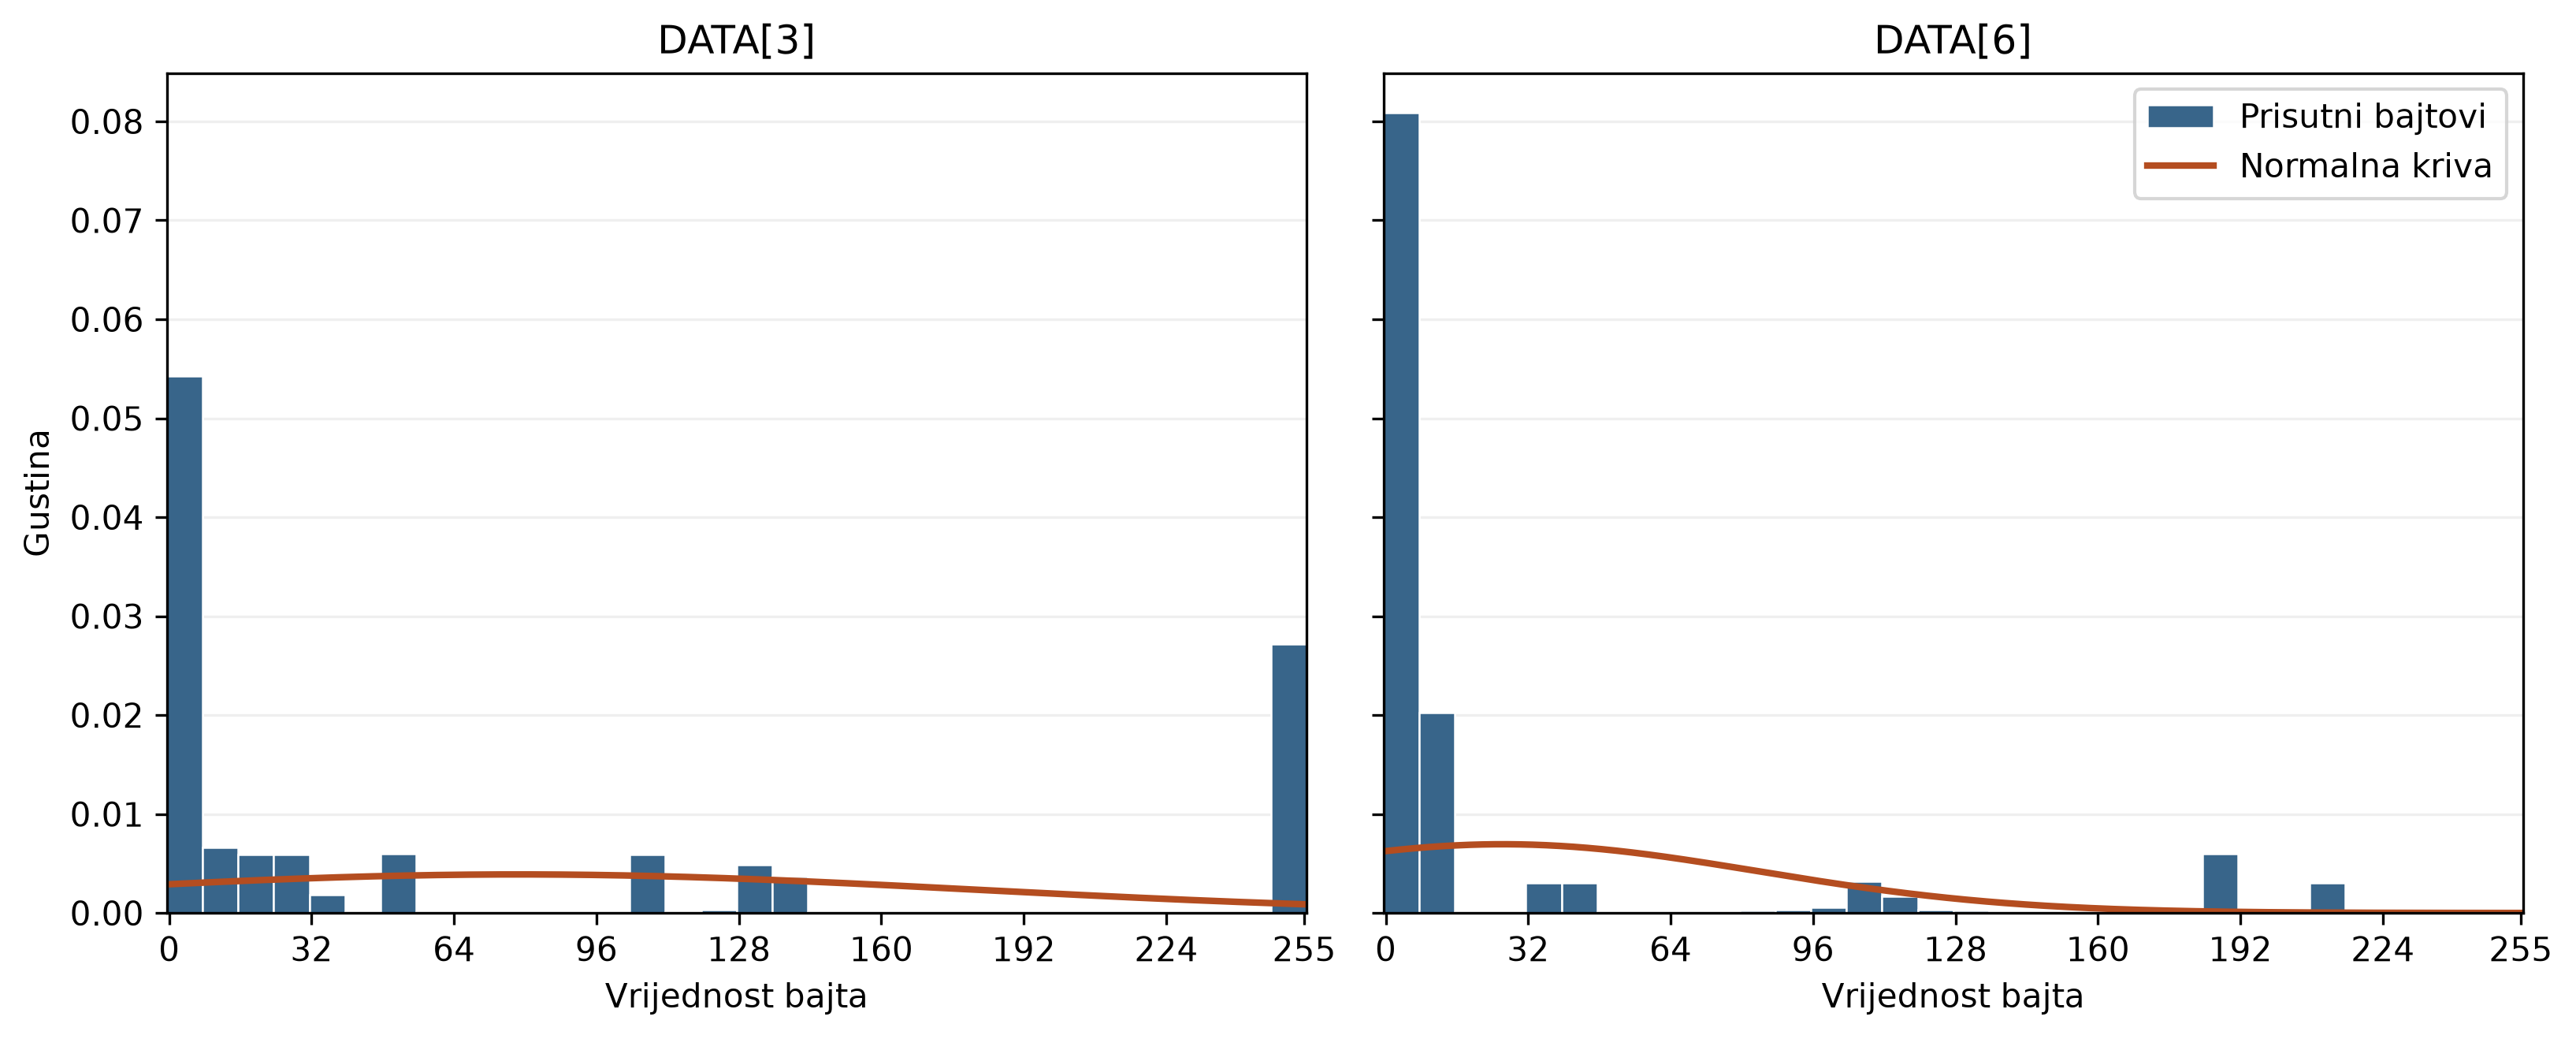

In [32]:
from IPython.display import Image, display

display(Image(filename="grafikon_4_histogrami_bajtova.png", width=900))

**Grafikon 4. Histogrami vrijednosti DATA[3] i DATA[6] s normalnim krivama**

Kod DATA[3] u intervalu 0–7 nalazi se 43,42 % vrijednosti, a u intervalu 248–255 još 21,75 %. Kod DATA[6] prvi interval obuhvata 64,67 % vrijednosti, a posljednji samo 0,10 %. Na obje pozicije najčešće su male vrijednosti, ali se kod DATA[3] izdvaja i grupa na gornjem kraju raspona. Te razlike u grupisanju normalne krive ne prikazuju dobro.

### 5.4. Vremenski razmak između uzastopnih CAN poruka

Za svaki snimak računam razliku između vremenskih oznaka dvije uzastopne poruke. Dobio sam 16.569.471 razmak, od kojih nijedan nije jednak nuli. Koristim rezultate skripte `vremenski_razmaci.py` da uporedim tipične i najduže razmake u četiri snimka.

In [34]:
import csv
from pathlib import Path
from IPython.display import Markdown, display

putanja = Path("vremenski_razmaci_po_snimku.csv")

with putanja.open(encoding="utf-8-sig", newline="") as ulaz:
    snimci = list(csv.DictReader(ulaz, delimiter=";"))


def formatiraj_broj(tekst, decimale):
    broj = float(tekst.replace(",", "."))
    return f"{broj:,.{decimale}f}".translate(str.maketrans(",.", ".,"))


def prikazi_pokazatelje(naslov, kolone):
    # Uz naziv svake kolone navodim broj decimala za prikaz.
    zaglavlje = ["Snimak", *kolone]
    linije = [
        "| " + " | ".join(zaglavlje) + " |",
        "| " + " | ".join(["---"] + ["---:"] * len(kolone)) + " |",
    ]

    for red in snimci:
        vrijednosti = [red["Snimak"]]
        for kolona, decimale in kolone.items():
            vrijednosti.append(formatiraj_broj(red[kolona], decimale))
        linije.append("| " + " | ".join(vrijednosti) + " |")

    display(Markdown(f"**{naslov}**\n\n" + "\n".join(linije)))


prikazi_pokazatelje(
    "Tabela 16. Broj opažanja, raspon i kvartili vremenskih razmaka po snimku",
    {
        "N": 0, "Min (ms)": 3, "Q1 (ms)": 3, "Medijan (ms)": 3,
        "Q3 (ms)": 3, "Maks (ms)": 3, "IQR (ms)": 3,
    },
)

prikazi_pokazatelje(
    "Tabela 17. Sredine, raspršenost i oblik raspodjele vremenskih razmaka po snimku",
    {
        "Sredina (ms)": 4, "Skraćena sredina (ms)": 4, "SD (ms)": 4,
        "CV (%)": 2, "Asimetričnost": 2, "Eksces": 2,
    },
)

**Tabela 16. Broj opažanja, raspon i kvartili vremenskih razmaka po snimku**

| Snimak | N | Min (ms) | Q1 (ms) | Medijan (ms) | Q3 (ms) | Maks (ms) | IQR (ms) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| DoS | 3.665.770 | 0,024 | 0,238 | 0,245 | 0,300 | 22.358,267 | 0,062 |
| Fuzzy | 3.838.859 | 0,022 | 0,236 | 0,244 | 0,414 | 2.539.482,308 | 0,178 |
| Gear | 4.443.141 | 0,015 | 0,236 | 0,243 | 0,309 | 5.588.125,845 | 0,073 |
| RPM | 4.621.701 | 0,015 | 0,236 | 0,243 | 0,304 | 7.744.934,786 | 0,068 |

**Tabela 17. Sredine, raspršenost i oblik raspodjele vremenskih razmaka po snimku**

| Snimak | Sredina (ms) | Skraćena sredina (ms) | SD (ms) | CV (%) | Asimetričnost | Eksces |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| DoS | 0,7727 | 0,5104 | 11,7664 | 1.522,70 | 1.871,43 | 3.555.886,16 |
| Fuzzy | 1,4294 | 0,5204 | 1.296,1170 | 90.677,41 | 1.959,30 | 3.838.844,19 |
| Gear | 1,8048 | 0,3820 | 2.651,0692 | 146.889,52 | 2.107,87 | 4.443.134,98 |
| RPM | 2,2024 | 0,3747 | 3.602,6061 | 163.573,49 | 2.149,81 | 4.621.695,44 |

Medijan je u sva četiri snimka između 0,243 i 0,245 ms. Fuzzy ima najširi interkvartilni raspon (0,178 ms), dok sam najduži pojedinačni razmak pronašao u RPM snimku (oko 129 minuta).

Uticaj dugih razmaka najbolje se vidi kod RPM snimka. Obična sredina iznosi 2,2024 ms, skraćena sredina 0,3747 ms, a medijan 0,243 ms. Za opis tipičnog razmaka zato sam se oslonio na medijan.

## 6. Ekstremne vrijednosti i provjera raspodjela

### 6.1. Provjera ekstremnih vrijednosti varijable DLC

Na frekvencije iz Tabele 7 primjenjujem IQR pravilo. Za svaku označenu dužinu prikazujem broj poruka i udio u cijelom skupu.

Q1 = 8, medijan = 8, Q3 = 8, IQR = 0
Donja granica: 8 bajtova
Gornja granica: 8 bajtova

Tabela 18. Poruke označene IQR pravilom prema dužini
DLC	Broj označenih poruka	Udio u svim porukama
2	147.211	0,888447 %
5	53.451	0,322587 %
6	3	0,000018 %
Ukupno	200.665	1,211052 %

Sačuvan grafikon: grafikon_5_boxplot_dlc.png


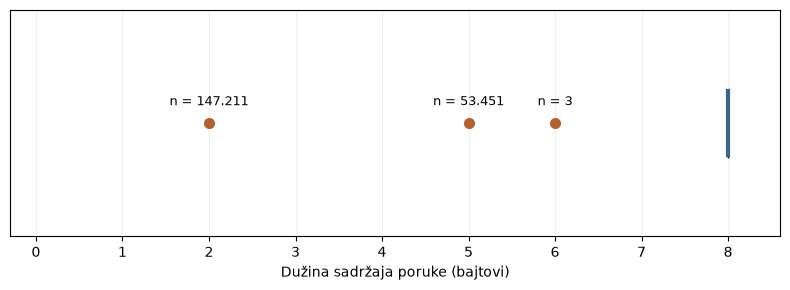

In [35]:
%run ekstremi_dlc.py

**Grafikon 5. Kutijasti dijagram dužine CAN poruka**

Obje granice IQR pravila iznose 8 bajtova. Pravilo je označilo svih 200.665 kraćih poruka (1,21 %). Najviše ih ima dva bajta, a samo tri imaju šest bajtova. Pošto je kod svake poruke broj zapisanih bajtova odgovarao DLC-u, sve sam ih zadržao u analizi.

### 6.2. Ekstremne vrijednosti bajtova sadržaja

IQR pravilo primjenjujem na svaku poziciju bajta zasebno. Udio označenih vrijednosti računam među prisutnim bajtovima te pozicije. Koristim tabelu i grafikon koje sam dobio skriptom `ekstremi_bajtovi.py`.

**Tabela 19. Vrijednosti bajtova označene IQR pravilom**

| Varijabla | N | Q1 | Q3 | IQR | Donja granica | Gornja granica | Ukupno označeno | Udio (%) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| DATA[0] | 16.569.475 | 0 | 69 | 69 | -103,5 | 172,5 | 2.996.105 | 18,0821 |
| DATA[1] | 16.569.475 | 0 | 69 | 69 | -103,5 | 172,5 | 919.907 | 5,5518 |
| DATA[2] | 16.422.264 | 0 | 96 | 96 | -144,0 | 240,0 | 86.462 | 0,5265 |
| DATA[3] | 16.422.264 | 0 | 137 | 137 | -205,5 | 342,5 | 0 | 0,0000 |
| DATA[4] | 16.422.264 | 0 | 107 | 107 | -160,5 | 267,5 | 0 | 0,0000 |
| DATA[5] | 16.368.813 | 0 | 127 | 127 | -190,5 | 317,5 | 0 | 0,0000 |
| DATA[6] | 16.368.810 | 0 | 10 | 10 | -15,0 | 25,0 | 3.115.389 | 19,0325 |
| DATA[7] | 16.368.810 | 0 | 109 | 109 | -163,5 | 272,5 | 0 | 0,0000 |

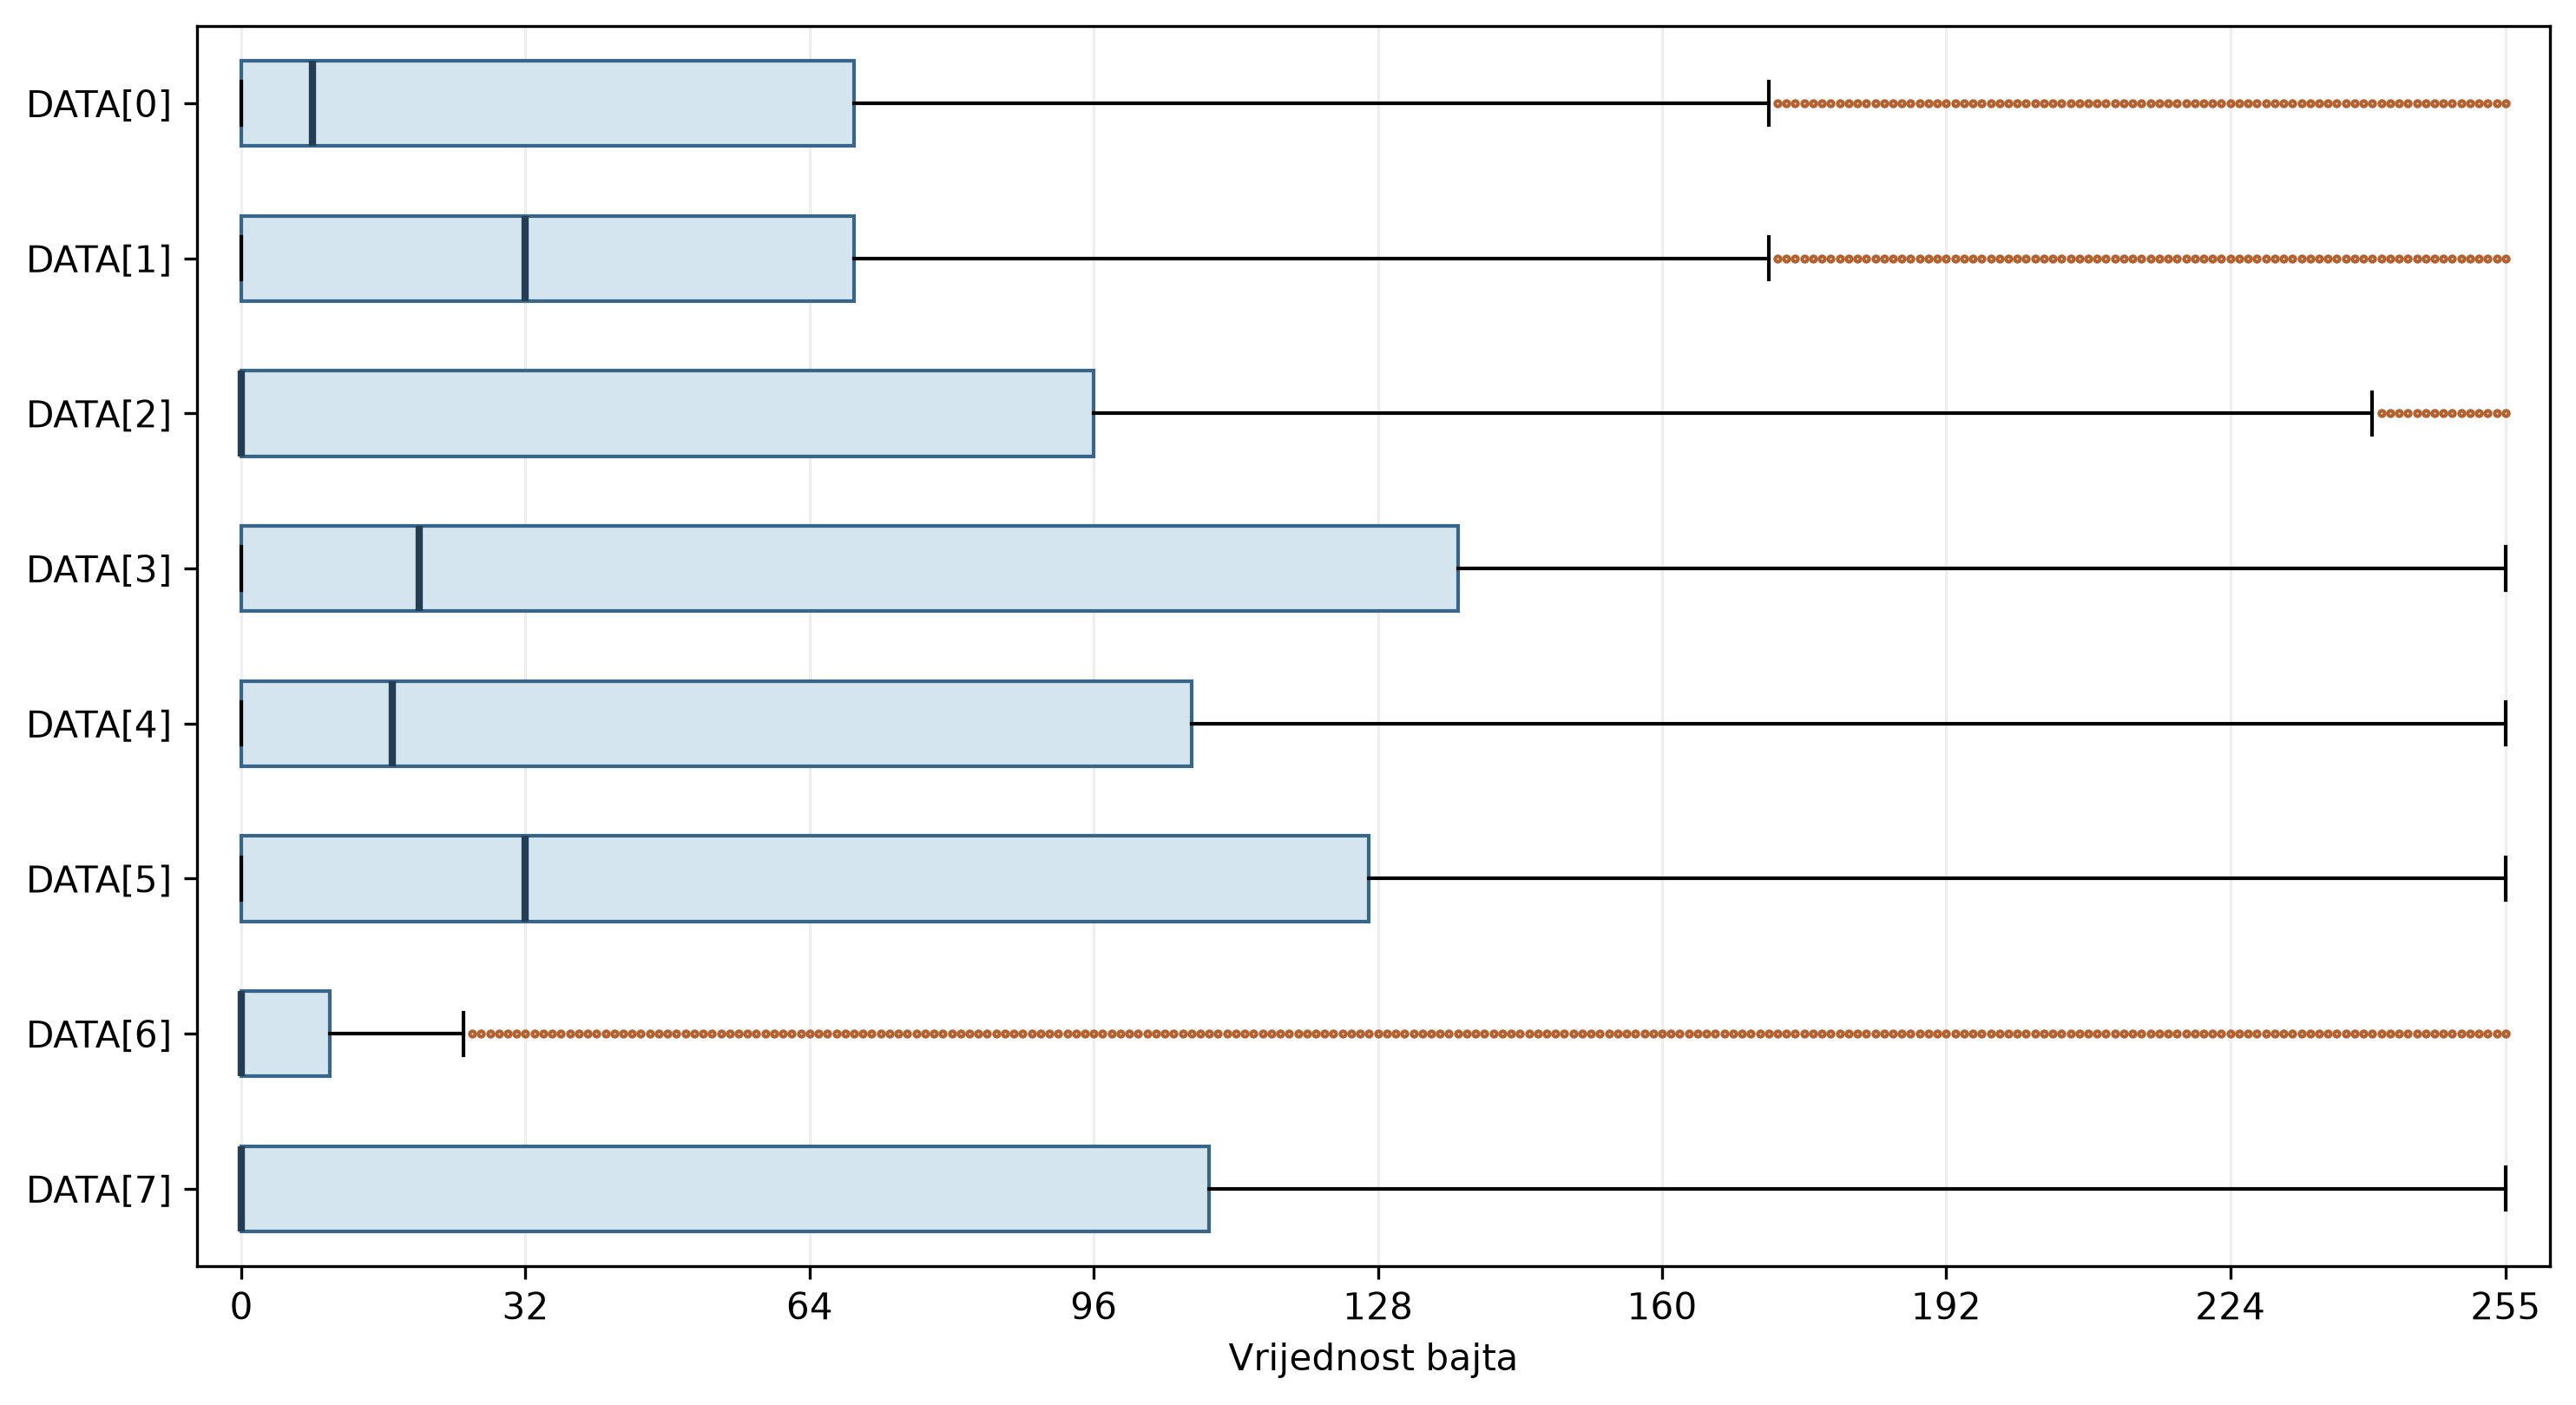

In [1]:
import csv
from pathlib import Path
from IPython.display import Image, Markdown, display

putanja = Path("ekstremi_bajtovi_iqr.csv")

with putanja.open(encoding="utf-8-sig", newline="") as ulaz:
    redovi = list(csv.DictReader(ulaz, delimiter=";"))

kolone = [
    "Varijabla", "N", "Q1", "Q3", "IQR", "Donja granica",
    "Gornja granica", "Ukupno označeno", "Udio (%)",
]

linije = [
    "| " + " | ".join(kolone) + " |",
    "| " + " | ".join(["---"] + ["---:"] * (len(kolone) - 1)) + " |",
]

for red in redovi:
    for kolona in ("N", "Ukupno označeno"):
        red[kolona] = f"{int(red[kolona]):,}".replace(",", ".")
    linije.append("| " + " | ".join(red[kolona] for kolona in kolone) + " |")

display(Markdown(
    "**Tabela 19. Vrijednosti bajtova označene IQR pravilom**\n\n"
    + "\n".join(linije)
))
display(Image(filename="grafikon_6_boxplot_bajtovi.png", width=900))

**Grafikon 6. Kutijasti dijagrami vrijednosti bajtova prema poziciji**

Najveći udio označenih vrijednosti pronašao sam kod DATA[6] (19,0325 %), gdje svaka vrijednost veća od 25 prelazi gornju granicu. Kod DATA[3] kutija je znatno šira i nijedna vrijednost ne prelazi granice. DATA[0] i DATA[1] imaju jednake kvartile, ali se vrijednosti iznad njihove zajedničke granice od 172,5 pojavljuju više od tri puta češće kod DATA[0]. Sve označene bajtove zadržao sam u analizi.

### 6.3. Ekstremni vremenski razmaci po snimku

Koristim kvartile iz dijela 5.4 i primjenjujem IQR pravilo posebno na DoS, Fuzzy, Gear i RPM snimak. Za svaki snimak prikazujem koliko je razmaka ispod donje i iznad gornje granice.

**Tabela 20. Vremenski razmaci označeni IQR pravilom po snimku**

| Snimak | N | Donja granica (ms) | Gornja granica (ms) | Ispod | Iznad | Ukupno označeno | Udio (%) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| DoS | 3.665.770 | 0,1450 | 0,3930 | 13.135 | 818.648 | 831.783 | 22,6905 |
| Fuzzy | 3.838.859 | -0,0310 | 0,6810 | 0 | 762.322 | 762.322 | 19,8580 |
| Gear | 4.443.141 | 0,1265 | 0,4185 | 205 | 975.215 | 975.420 | 21,9534 |
| RPM | 4.621.701 | 0,1340 | 0,4060 | 653 | 1.025.263 | 1.025.916 | 22,1978 |

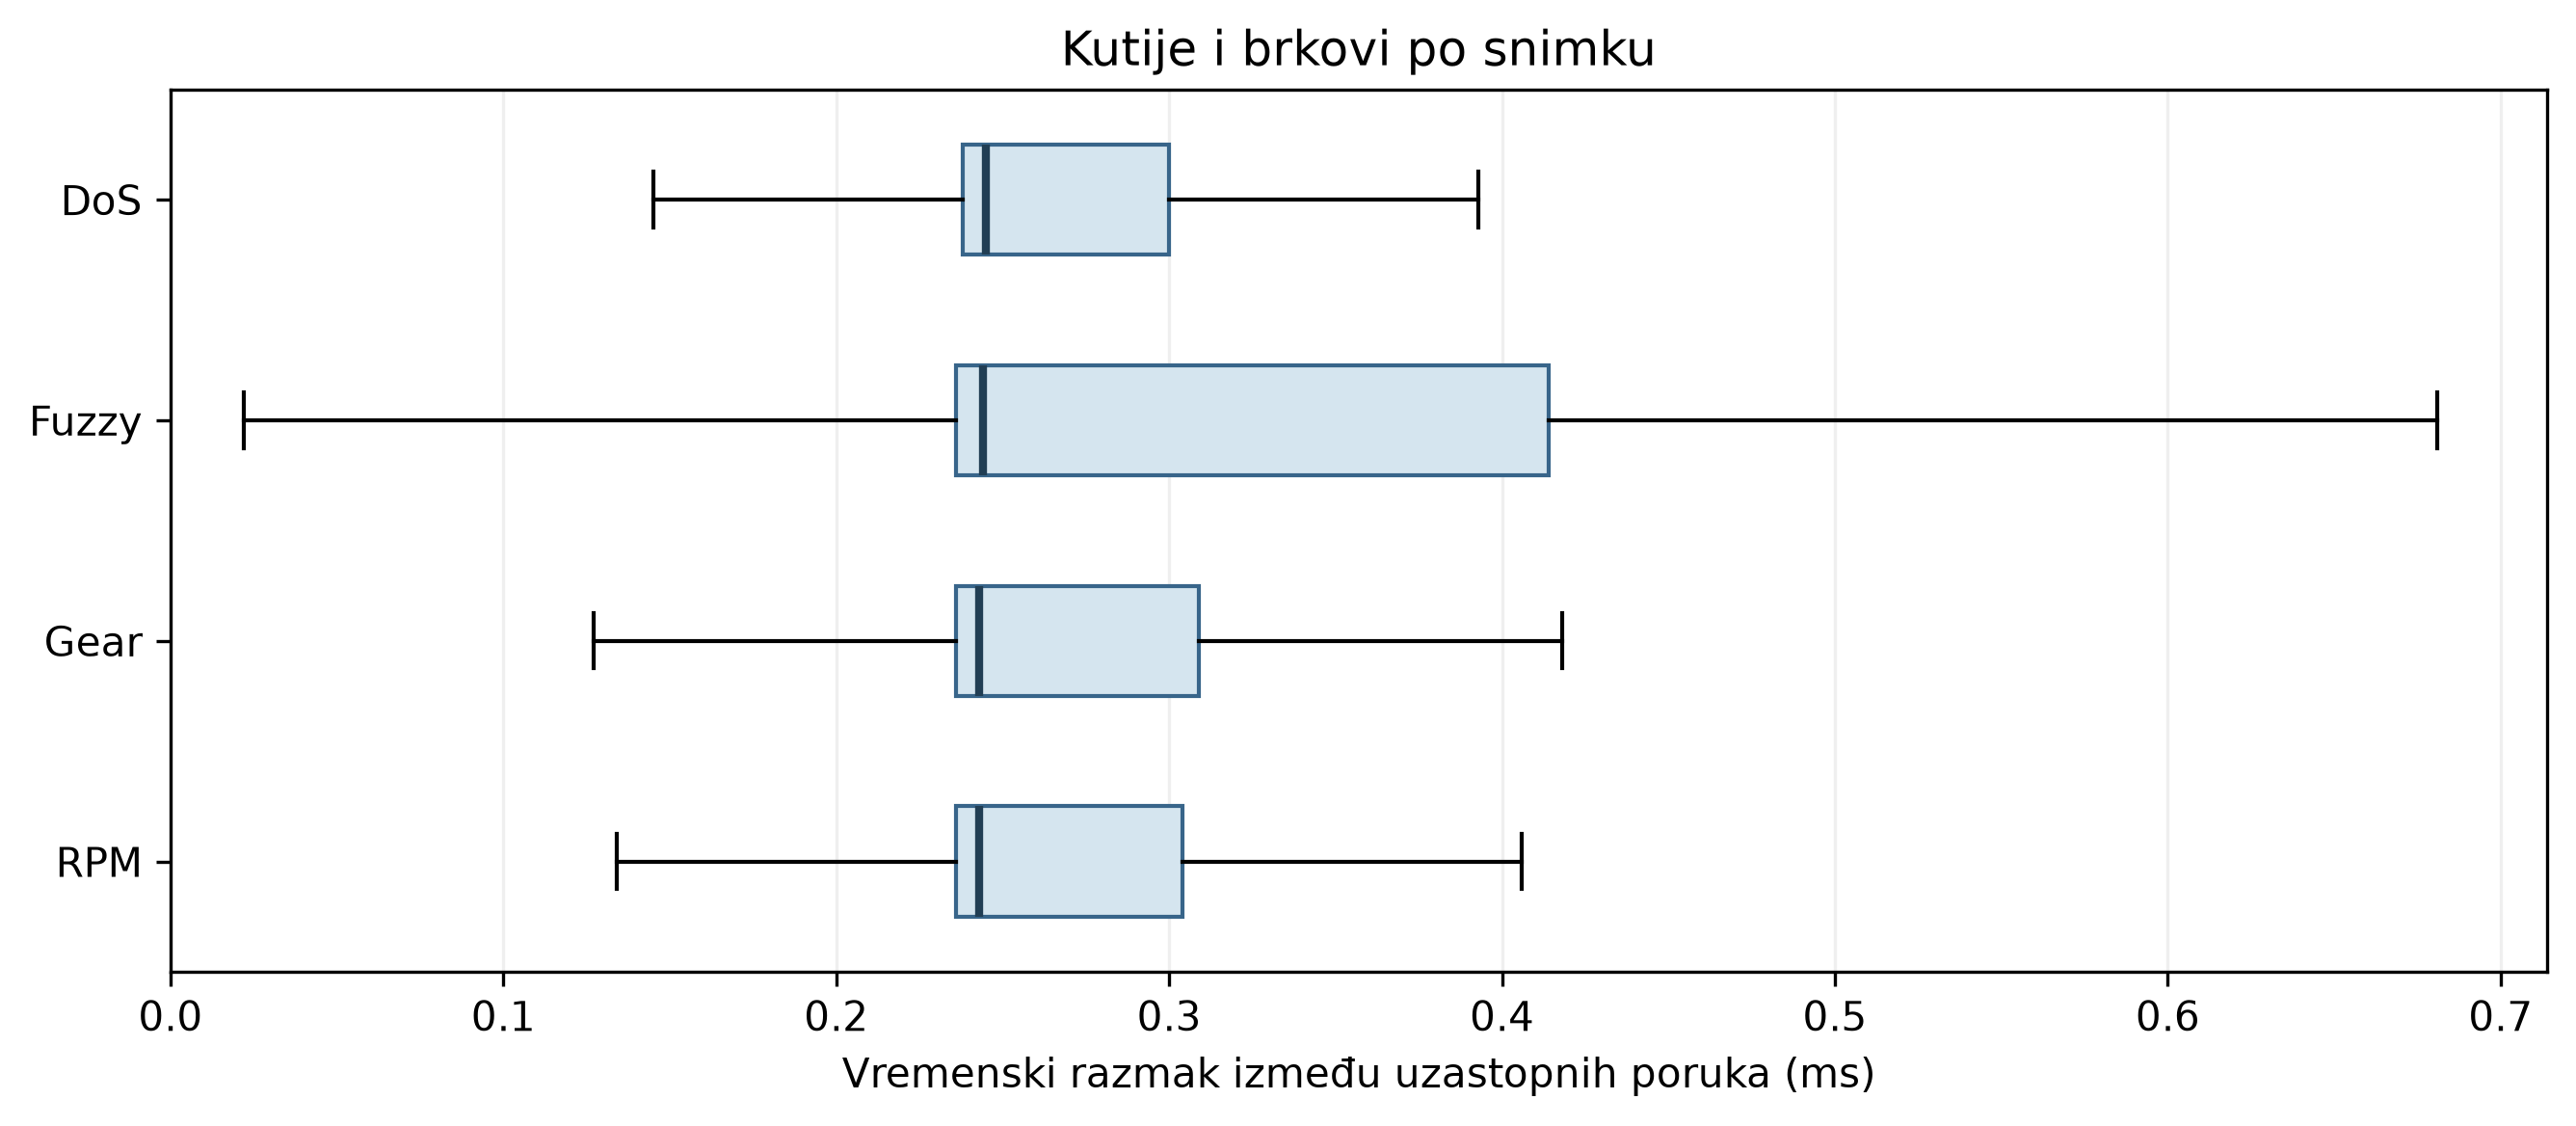

In [2]:
import csv
from pathlib import Path
from IPython.display import Markdown, Image, display

putanja = Path("ekstremi_vremenski_razmaci.csv")

with putanja.open(encoding="utf-8-sig", newline="") as ulaz:
    citac = csv.DictReader(ulaz, delimiter=";")
    kolone = citac.fieldnames
    redovi = list(citac)

linije = [
    "| " + " | ".join(kolone) + " |",
    "| " + " | ".join(["---"] + ["---:"] * (len(kolone) - 1)) + " |",
]

for red in redovi:
    for kolona in ("N", "Ispod", "Iznad", "Ukupno označeno"):
        red[kolona] = f"{int(red[kolona]):,}".replace(",", ".")
    linije.append("| " + " | ".join(red[kolona] for kolona in kolone) + " |")

display(Markdown(
    "**Tabela 20. Vremenski razmaci označeni IQR pravilom po snimku**\n\n"
    + "\n".join(linije)
))
display(Image(filename="grafikon_7_boxplot_vremenski_razmaci.png", width=850))

**Grafikon 7. Kutijasti dijagrami vremenskih razmaka po snimku**

Medijani su u sva četiri snimka blizu 0,24 ms. Najširu kutiju ima Fuzzy, koji ujedno ima najmanji udio označenih razmaka (19,86 %). Najveći udio ima DoS (22,69 %). Kada sam sabrao rezultate za sva četiri snimka, utvrdio sam da je 99,61 % označenih razmaka iznad gornje granice. Broj tih razmaka vidi se u Tabeli 20, dok grafikon prikazuje kutije i brkove.

## 7. Odnosi među varijablama i višerazinska analiza

### 7.1. Odnos između vrijednosti DATA[3] i DATA[6]

Posmatram četvrti i sedmi bajt unutar iste CAN poruke. Poredim udio nula na poziciji DATA[6] između dvije grupe poruka, a zatim na raspršenom dijagramu prikazujem učestalost svakog zabilježenog para.

**Tabela 21. Udio nula na poziciji DATA[6] prema vrijednosti DATA[3]**

| Grupa poruka | Broj parova | Broj poruka s DATA[6] = 0 | Udio unutar grupe (%) |
|---|---:|---:|---:|
| DATA[3] = 0 | 7.056.473 | 4.102.714 | 58,14 |
| DATA[3] > 0 | 9.312.337 | 5.345.072 | 57,40 |
| Ukupno | 16.368.810 | 9.447.786 | 57,72 |

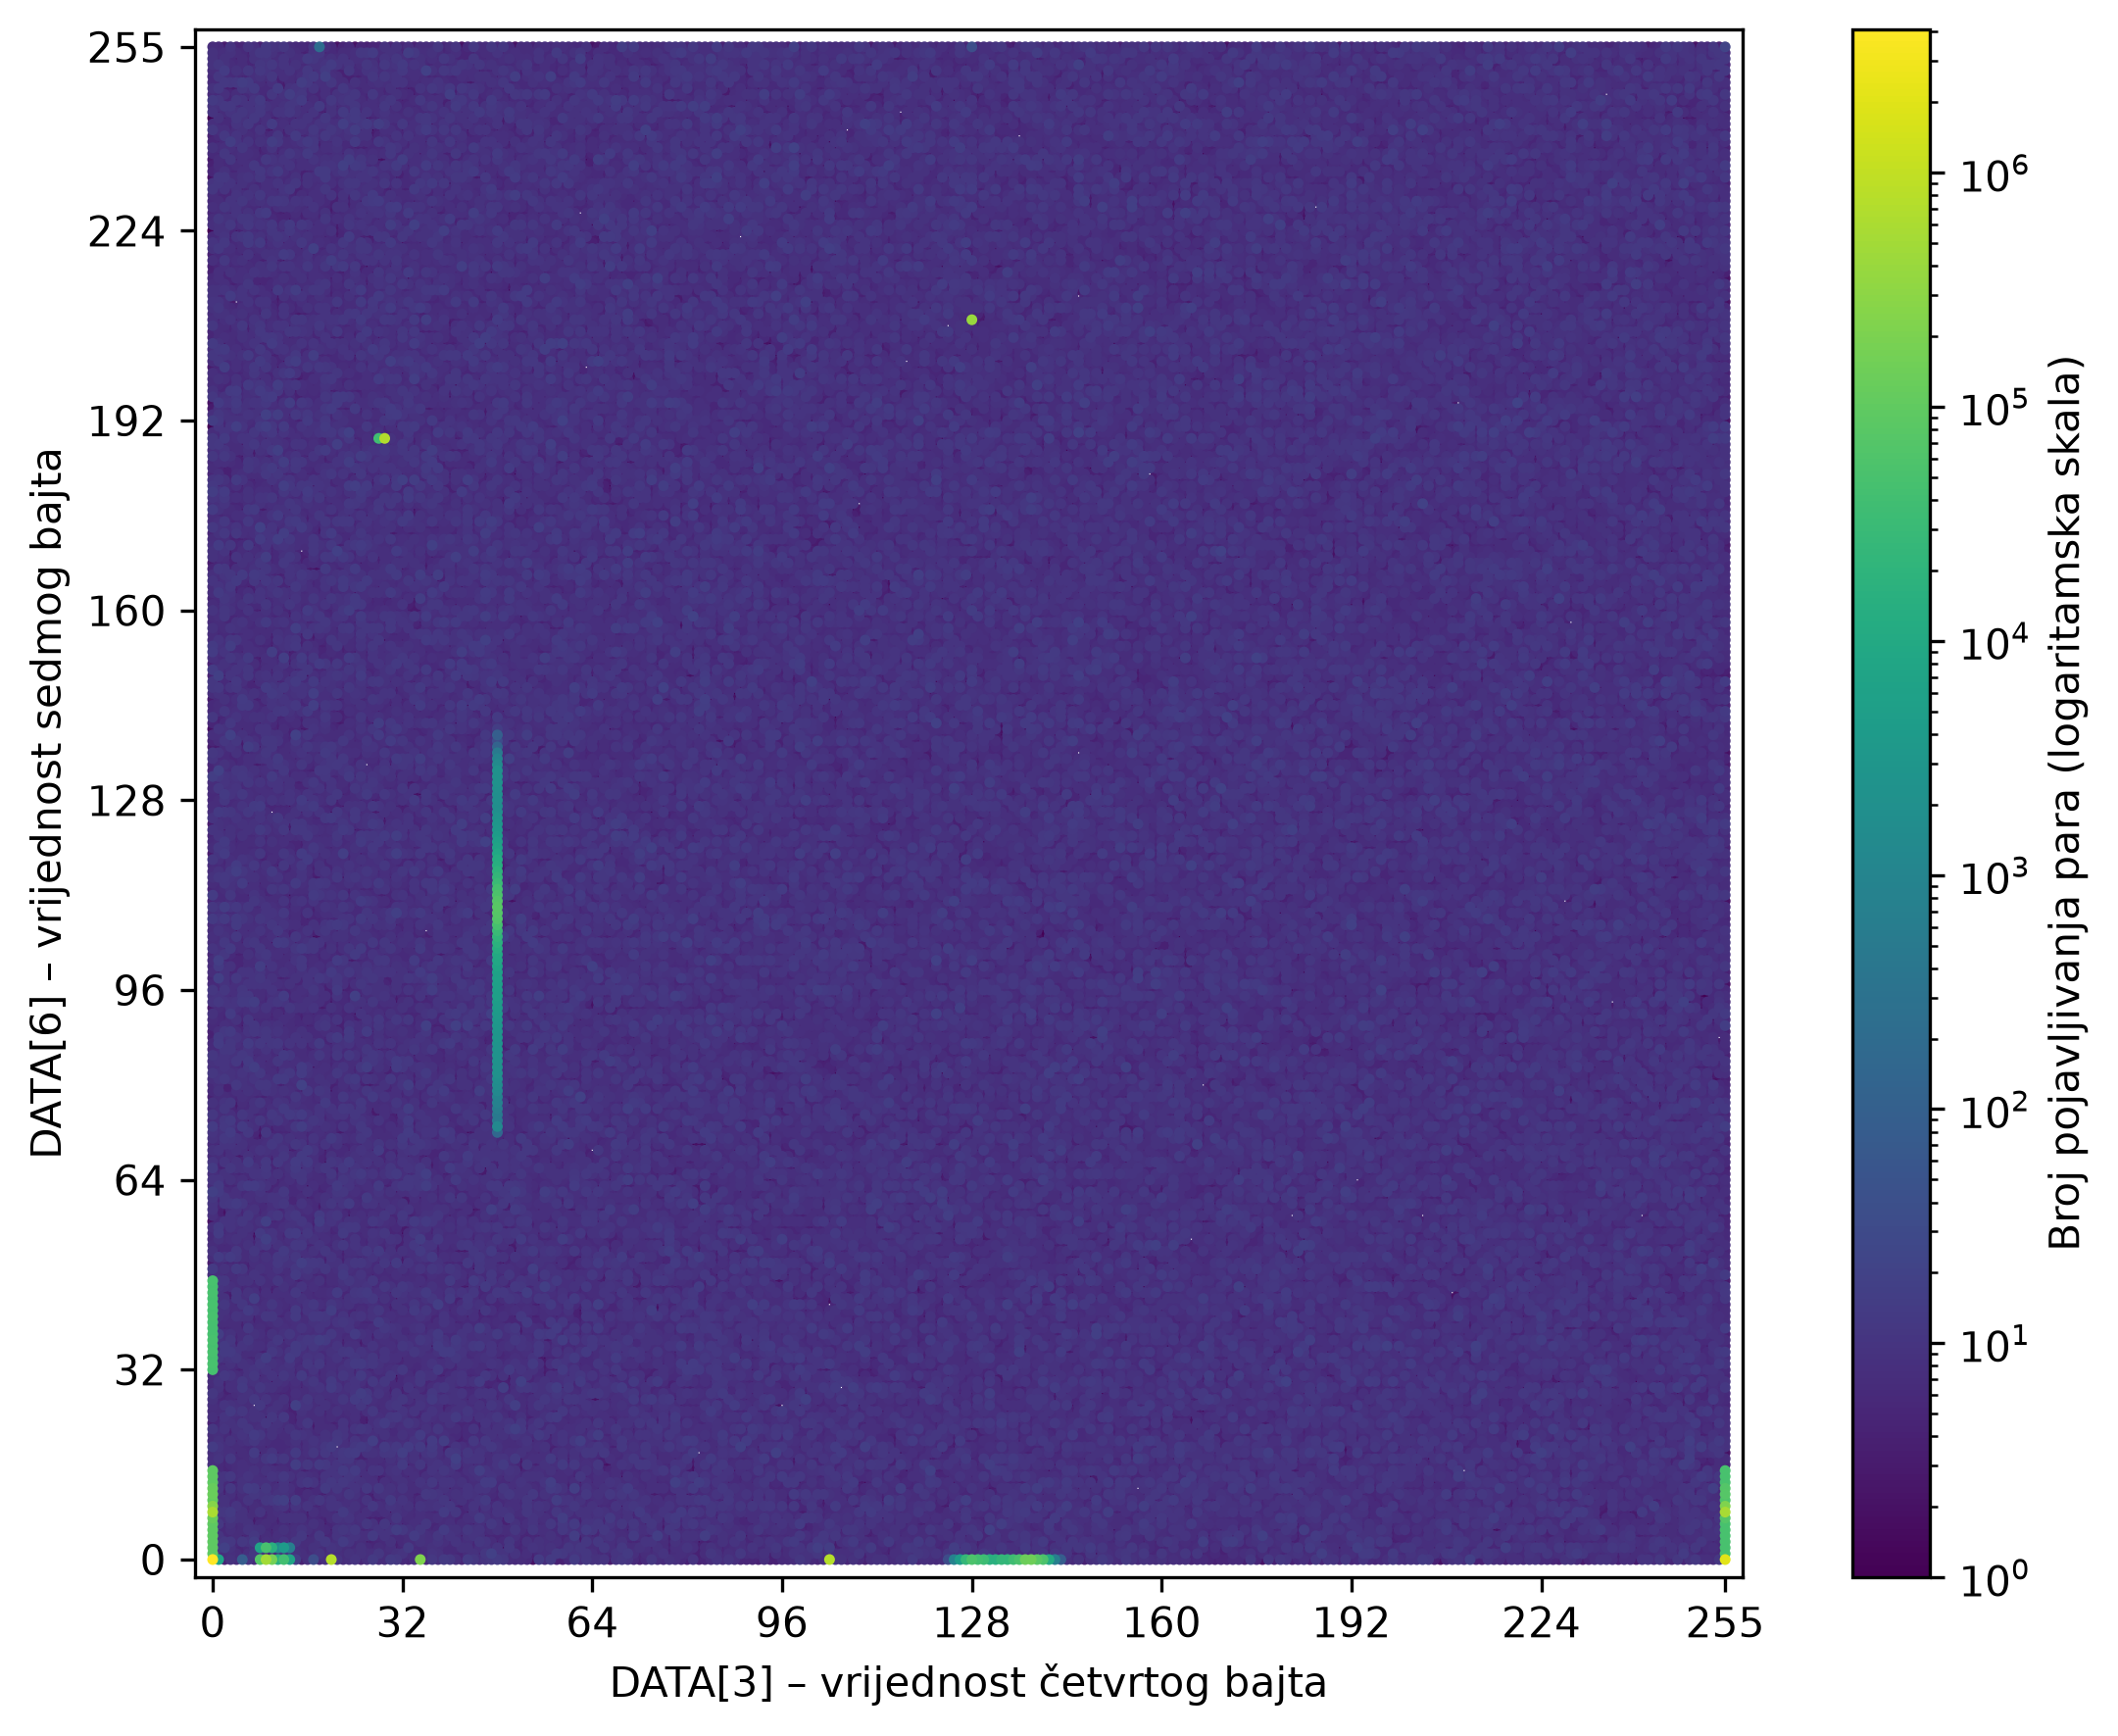

In [3]:
import csv
from pathlib import Path
from IPython.display import Image, Markdown, display

putanja = Path("odnos_bajtova_data3_data6.csv")

with putanja.open(encoding="utf-8-sig", newline="") as ulaz:
    redovi = list(csv.DictReader(ulaz, delimiter=";"))

linije = [
    "| Grupa poruka | Broj parova | Broj poruka s DATA[6] = 0 | Udio unutar grupe (%) |",
    "|---|---:|---:|---:|",
]

for red in redovi:
    broj_parova = f"{int(red['Broj parova']):,}".replace(",", ".")
    broj_nula = f"{int(red['Broj s DATA[6] = 0']):,}".replace(",", ".")
    grupa = red["Grupa poruka"]
    udio = red["Udio s DATA[6] = 0 (%)"]
    linije.append(f"| {grupa} | {broj_parova} | {broj_nula} | {udio} |")

display(Markdown(
    "**Tabela 21. Udio nula na poziciji DATA[6] prema vrijednosti DATA[3]**\n\n"
    + "\n".join(linije)
))
display(Image(filename="grafikon_8_odnos_data3_data6.png", width=800))

**Grafikon 8. Raspršeni dijagram vrijednosti DATA[3] i DATA[6] u istoj CAN poruci**

U Tabeli 21 udio nula na sedmoj poziciji razlikuje se za samo 0,74 procentna poena između dvije grupe. Kod pojedinačnih parova uočio sam izraženu koncentraciju: pet od 65.496 zabilježenih kombinacija obuhvata 51,46 % svih posmatranih poruka. Najčešći par (0, 0) sam čini približno četvrtinu svih parova.

### 7.2. Vremenski razmak prije redovnih i ubačenih poruka

Svaki razmak pridružujem oznaci poruke koja je upravo stigla. Za svaki snimak posebno upoređujem medijan i interkvartilni raspon prije redovnih (R) i ubačenih (T) poruka.

**Tabela 22. Vremenski razmak prije redovnih i ubačenih poruka po snimku**

| Snimak | Oznaka | N | Q1 (ms) | Medijan (ms) | Q3 (ms) | IQR (ms) |
|---|---|---:|---:|---:|---:|---:|
| DoS | R | 3.078.249 | 0,2380 | 0,2440 | 0,2580 | 0,0200 |
| DoS | T | 587.521 | 0,2450 | 0,2470 | 0,4920 | 0,2470 |
| Fuzzy | R | 3.347.012 | 0,2370 | 0,2430 | 0,2610 | 0,0240 |
| Fuzzy | T | 491.847 | 0,2240 | 0,4020 | 0,8920 | 0,6680 |
| Gear | R | 3.845.889 | 0,2370 | 0,2430 | 0,2540 | 0,0170 |
| Gear | T | 597.252 | 0,2320 | 0,3290 | 1,1090 | 0,8770 |
| RPM | R | 3.966.804 | 0,2380 | 0,2430 | 0,2530 | 0,0150 |
| RPM | T | 654.897 | 0,2260 | 0,3150 | 1,0580 | 0,8320 |

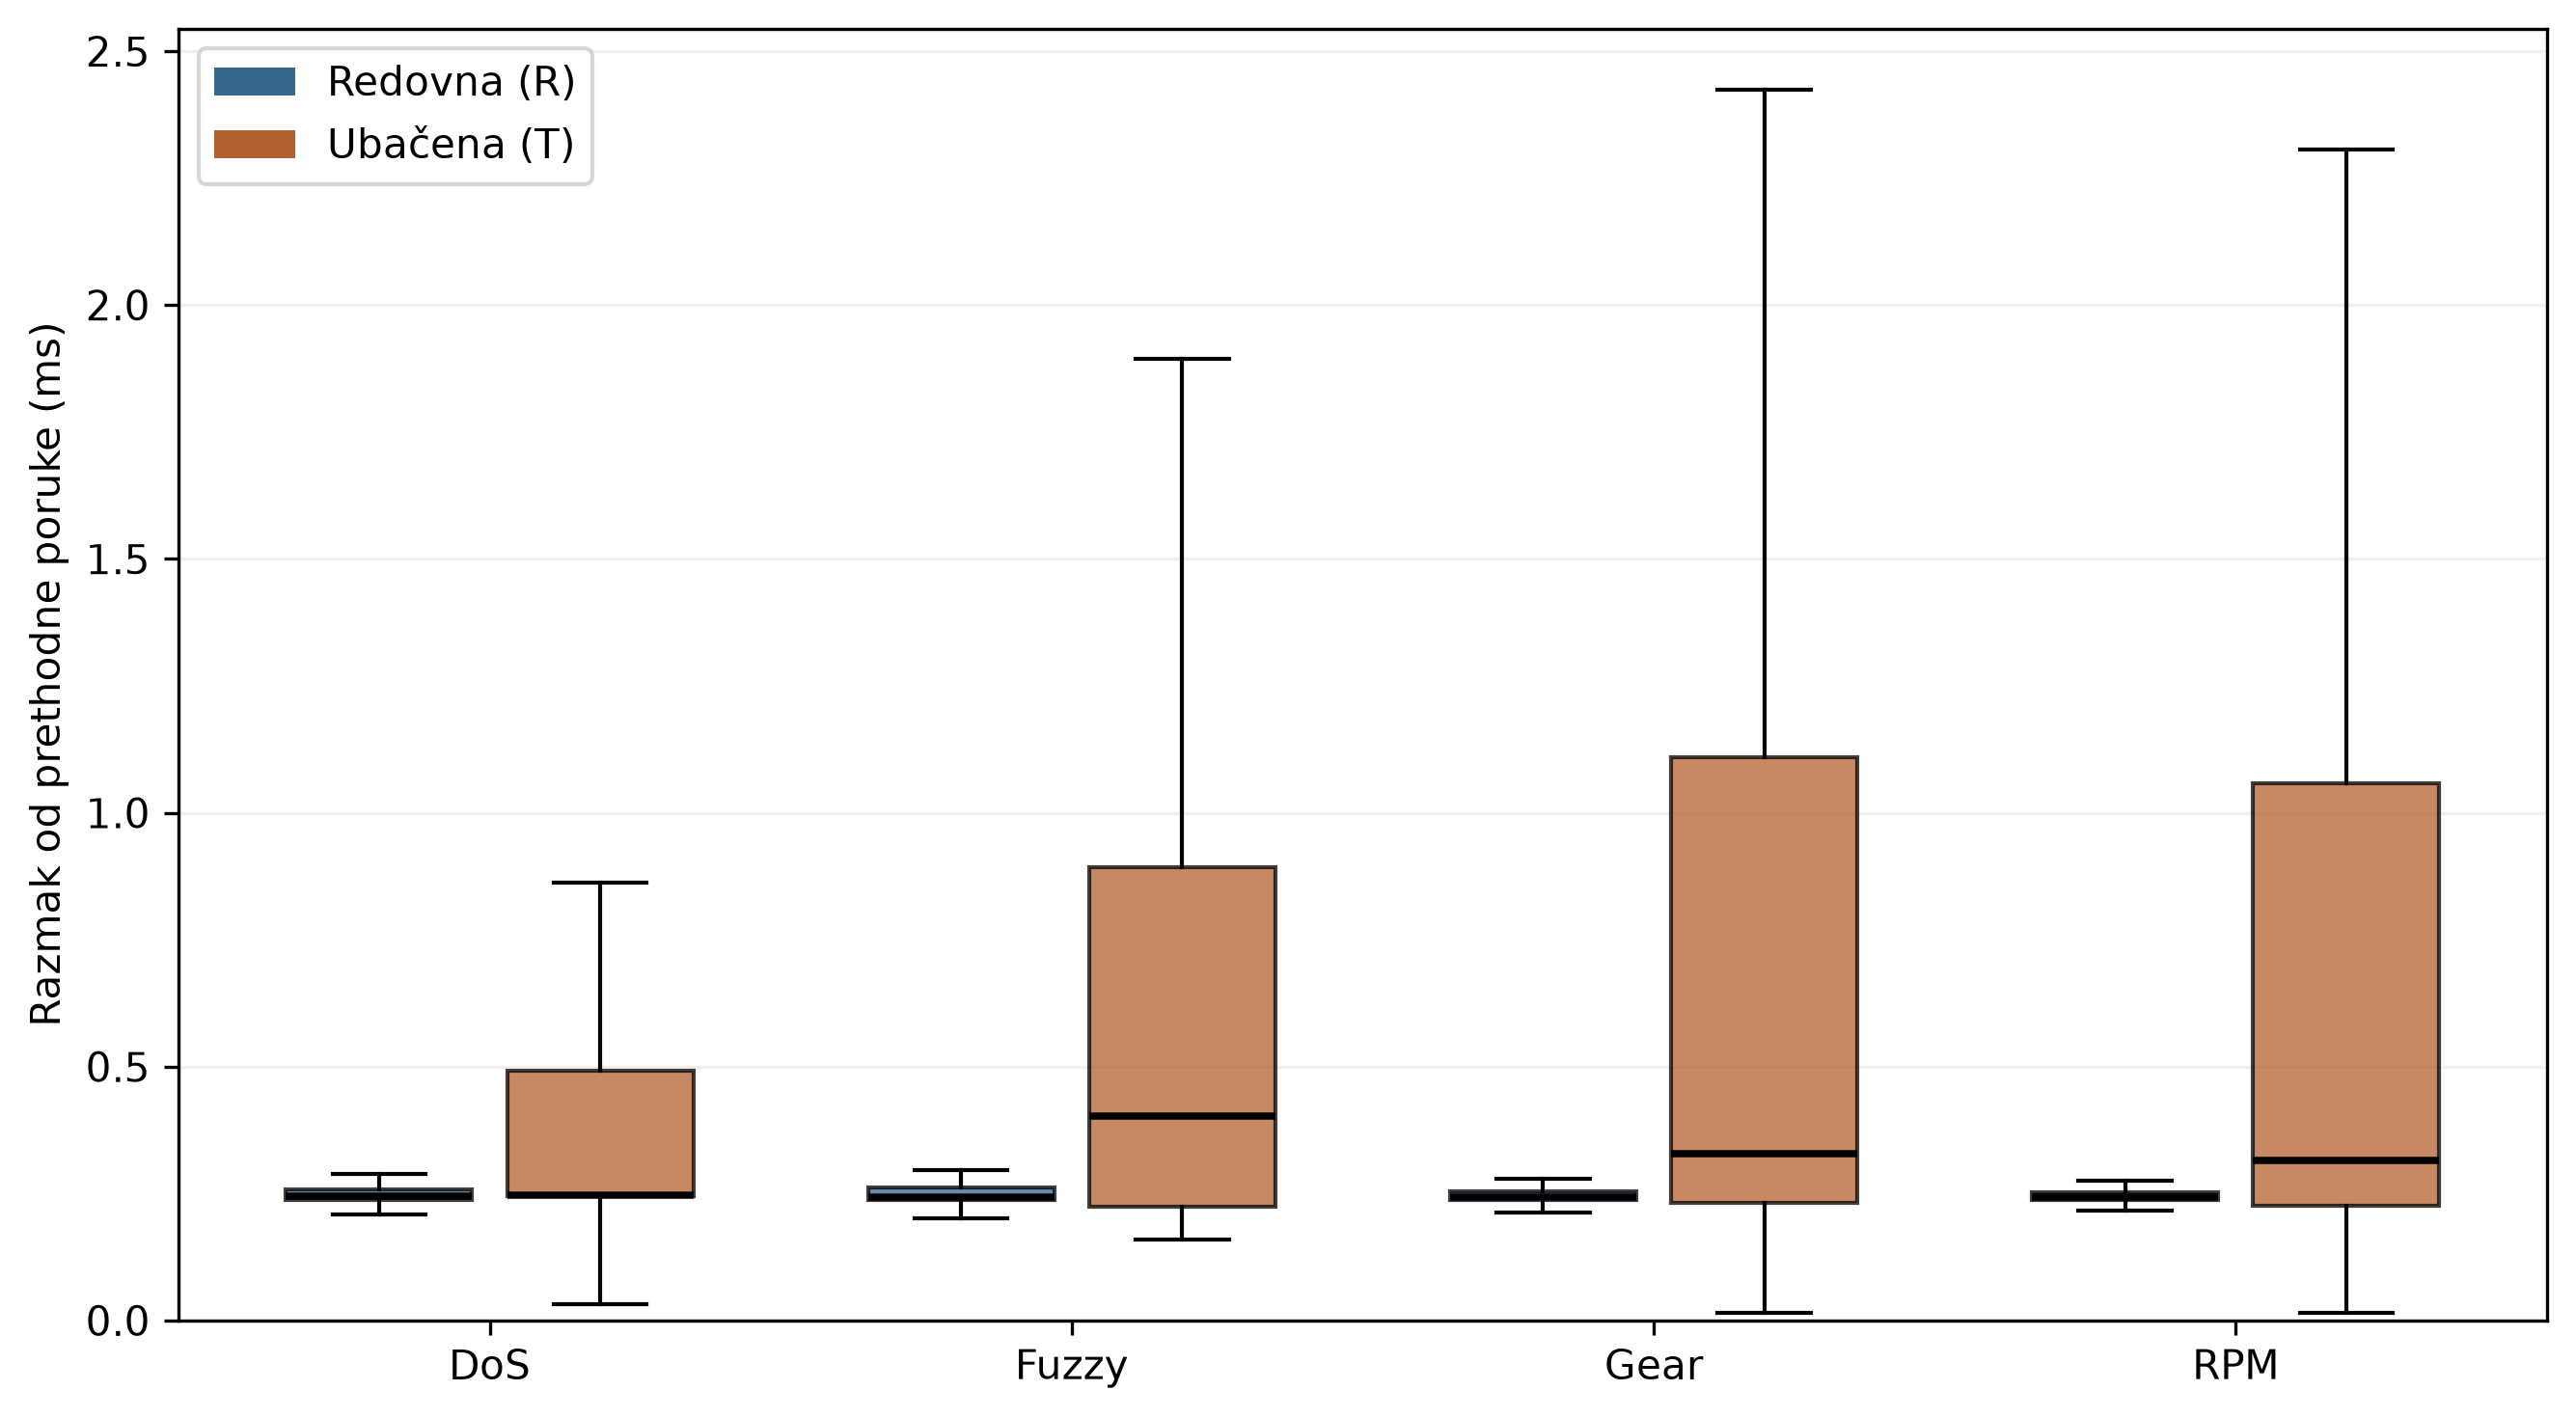

In [4]:
import csv
from pathlib import Path
from IPython.display import Image, Markdown, display

putanja = Path("razmaci_prema_oznaci.csv")

with putanja.open(encoding="utf-8-sig", newline="") as ulaz:
    citac = csv.DictReader(ulaz, delimiter=";")
    kolone = citac.fieldnames
    redovi = list(citac)

linije = [
    "| " + " | ".join(kolone) + " |",
    "|---|---|---:|---:|---:|---:|---:|",
]

for red in redovi:
    red["N"] = f"{int(red['N']):,}".replace(",", ".")
    linije.append("| " + " | ".join(red[kolona] for kolona in kolone) + " |")

display(Markdown(
    "**Tabela 22. Vremenski razmak prije redovnih i ubačenih poruka po snimku**\n\n"
    + "\n".join(linije)
))
display(Image(filename="grafikon_9_razmaci_prema_oznaci.png", width=850))

**Grafikon 9. Raspodjela vremenskih razmaka prije redovnih i ubačenih poruka po snimku**

U sva četiri snimka razmaci prije ubačenih poruka imaju veći interkvartilni raspon. U DoS snimku medijani se razlikuju za samo 0,003 ms, ali IQR iznosi 0,020 ms za R i 0,247 ms za T. Najveću razliku medijana uočio sam u Fuzzy snimku (0,159 ms), a najveću raspršenost srednjih 50 % razmaka kod ubačenih poruka u Gear snimku (IQR = 0,877 ms).

### 7.3. Odnos između CAN identifikatora i oznake poruke po snimku

U Tabeli 11 udjeli ubačenih poruka za identifikatore 0316 i 043f razlikuju se za samo 1,98 procentnih poena kada posmatram sve snimke zajedno. U Tabeli 12 i na Grafikonu 3 vidi se zašto je važno razdvojiti snimke.

U Gear snimku oznaku T ima 74,24 % poruka s identifikatorom 043f i 0 % poruka s identifikatorom 0316. U RPM snimku oznaku T ima 75,17 % poruka s identifikatorom 0316 i 0 % poruka s identifikatorom 043f. Tako dva identifikatora sa sličnim ukupnim udjelima pokazuju različite obrasce unutar pojedinačnih snimaka.

## 8. Korelacijska analiza

### 8.1. Izbor varijabli i način računanja

Za osam pozicija bajtova računam Spearmanov koeficijent korelacije. Svaki par obuhvata poruke u kojima su oba bajta prisutna. Jednake vrijednosti dobijaju isti prosječni rang. CAN ID i Flag izostavljam jer predstavljaju kategorije.

### 8.2. Rezultati korelacijske analize

Od 28 različitih parova izdvajam tri s najvećom apsolutnom korelacijom. Na heatmapi prikazujem cijelu matricu.

**Tabela 23. Tri para s najvećom apsolutnom Spearmanovom korelacijom**

| Prva pozicija | Druga pozicija | Broj prisutnih parova | Spearmanov ρ |
|---|---|---:|---:|
| DATA[2] | DATA[3] | 16.422.264 | 0,5442 |
| DATA[2] | DATA[4] | 16.422.264 | 0,5291 |
| DATA[5] | DATA[6] | 16.368.810 | 0,4712 |

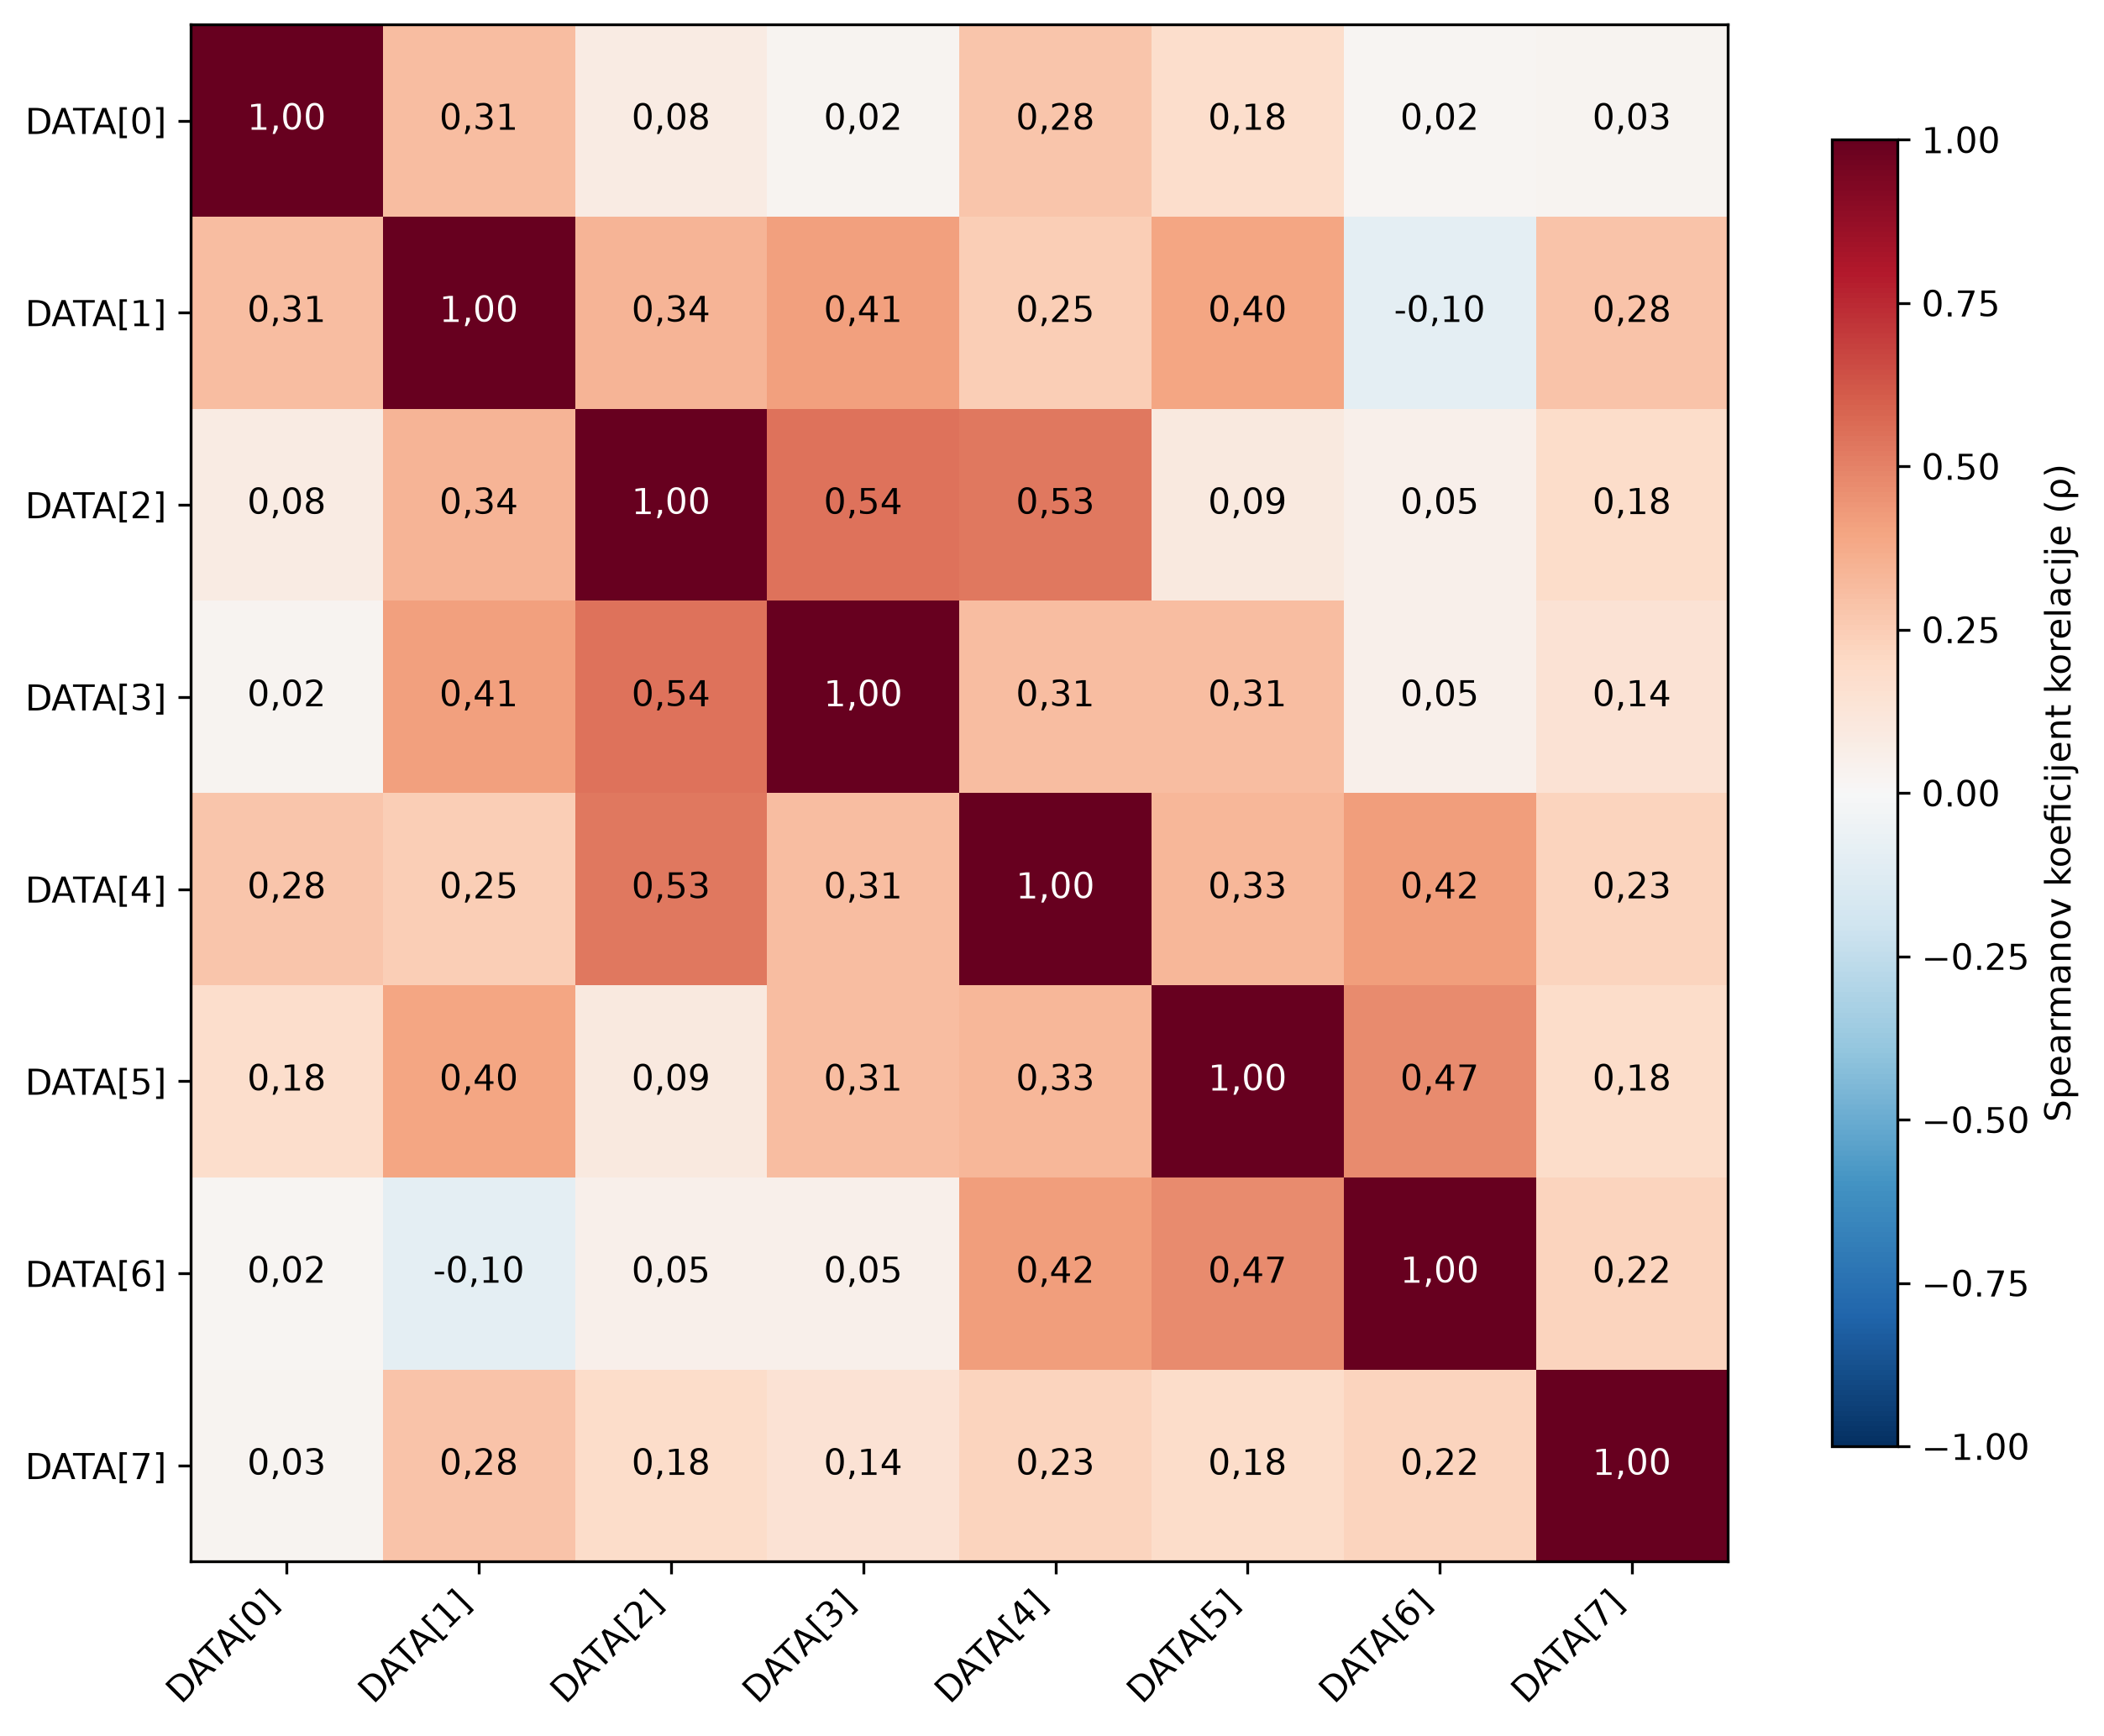

In [5]:
import csv
from pathlib import Path
from IPython.display import Image, Markdown, display

putanja = Path("korelacija_bajtova_spearman.csv")

with putanja.open(encoding="utf-8-sig", newline="") as ulaz:
    rezultati = list(csv.DictReader(ulaz, delimiter=";"))

linije = [
    "| Prva pozicija | Druga pozicija | Broj prisutnih parova | Spearmanov ρ |",
    "|---|---|---:|---:|",
]

for red in rezultati[:3]:
    prva = red["Prva pozicija"]
    druga = red["Druga pozicija"]
    broj = f"{int(red['Broj parova']):,}".replace(",", ".")
    rho = float(red["Spearman ρ"].replace(",", "."))
    koeficijent = f"{rho:.4f}".replace(".", ",")
    linije.append(f"| {prva} | {druga} | {broj} | {koeficijent} |")

display(Markdown(
    "**Tabela 23. Tri para s najvećom apsolutnom Spearmanovom korelacijom**\n\n"
    + "\n".join(linije)
))
display(Image(filename="grafikon_10_heatmapa_bajtovi.png", width=800))

**Grafikon 10. Heatmapa Spearmanovih korelacija između pozicija bajtova**

Najjaču pozitivnu povezanost uočio sam kod parova DATA[2] i DATA[3] (ρ = 0,5442), DATA[2] i DATA[4] (ρ = 0,5291) te DATA[5] i DATA[6] (ρ = 0,4712). Sve tri povezanosti su umjerene. Jedini negativan koeficijent dobio sam za DATA[1] i DATA[6] (ρ ≈ −0,10).

Par iz dijela 7.1, DATA[3] i DATA[6], ima koeficijent blizu nule (ρ ≈ 0,05). Na raspršenom dijagramu izdvojile su se česte kombinacije poput (0, 0) i (255, 0), dok heatmapa pokazuje da kroz sve poruke nema izraženog zajedničkog rasta ili pada vrijednosti na te dvije pozicije.

## 9. Prijedlog postupanja s nedostajućim i problematičnim podacima

### 9.1. Nepopunjene pozicije bajtova

Svih 16.569.475 poruka ima sve vrijednosti koje se očekuju prema DLC-u. Kod 200.665 kraćih poruka pozicije nakon posljednjeg bajta nisu primjenjive. Ostavljam ih prazne i pri računanju pokazatelja koristim samo prisutne bajtove. Dopunjavanje nulom, sredinom ili medijanom dodalo bi sadržaj kojeg nema u poruci, čak i kada bih vrijednost za dopunu računao unutar istog CAN ID-a.

### 9.2. Potpuno jednaki zapisi između datoteka

Unutar pojedinačnih snimaka nema potpuno jednakih redova. Između četiri snimka pronašao sam 2.673.204 dodatna pojavljivanja. Predlažem zadržavanje svakog zapisa u njegovom snimku. Pri tumačenju zbirnih rezultata uzimam u obzir preklapanje datoteka.

### 9.3. Vrijednosti označene IQR pravilom

**Tabela 24. Prijedlog postupanja s izdvojenim podacima**

| Izdvojeni podaci | Obuhvat | Prijedlog |
|---|---:|---|
| Kraće poruke | 200.665 (1,21 %) | Zadržati izvorni DLC i prisutne bajtove. |
| Jednaki zapisi između datoteka | 2.673.204 dodatna pojavljivanja | Zadržati pripadnost snimku i navesti preklapanje. |
| Bajtovi izvan IQR granica | 0–19,03 % po poziciji | Zadržati i po potrebi provjeriti unutar istog CAN ID-a. |
| Razmaci izvan IQR granica | 3.595.441 (21,70 %) | Zadržati i zasebno provjeriti najduže razmake. |

Kod bajtova oznaka zavisi od raspodjele na konkretnoj poziciji. Kod vremenskih razmaka automatskim uklanjanjem izgubio bih više od petine opažanja. Zato rezultate IQR provjere koristim za opis raspodjele i odabir vrijednosti koje zaslužuju dodatnu provjeru.

## 10. Normalizacija, standardizacija i transformacije

### 10.1. Procjena potrebe za skaliranjem

Svih osam pozicija bajtova već ima zajedničku skalu od 0 do 255. Podjelom sa 255 dobio bih raspon od 0 do 1, uz isti oblik raspodjele i isti udio nula. DLC zadržavam kao broj bajtova. Kod njega je IQR jednak nuli, pa izraz `(DLC − medijan) / IQR` nije definisan.

### 10.2. Moguća transformacija vremenskih razmaka

U RPM snimku medijan iznosi 0,243 ms, a najduži razmak oko 129 minuta. Za prikaz cijelog raspona razmotrio bih `ln(1 + t)`, gdje je `t` brojčana vrijednost razmaka u milisekundama. Svi posmatrani razmaci su pozitivni. Logaritamska transformacija smanjila bi razlike između najvećih vrijednosti i sačuvala njihov redoslijed.

**Tabela 25. Prijedlog skaliranja i transformacije prema osobinama varijabli**

| Varijabla | Postupak | Svrha |
|---|---|---|
| DATA[0]–DATA[7] | Zadržati 0–255 ili podijeliti sa 255 | Izvorni bajtovi su direktno uporedivi. Podjelom se dobija skala 0–1. |
| DLC | Zadržati broj bajtova | Vrijednosti su lako razumljive, a IQR je 0. |
| Vremenski razmak u ms | Razmotriti `ln(1 + t)` | Prikazati kratke i veoma duge razmake na zajedničkoj osi. |
| Vremenski razmak unutar snimka | Razmotriti `(t − medijan) / IQR` | Izraziti odstupanje od tipičnog razmaka unutar snimka. |

Za poređenje stvarnog trajanja između snimaka zadržao bih milisekunde. Predložene postupke nisam primijenio na izvorne podatke.

## 11. Sažetak nalaza eksploratorne analize

U četiri snimka analizirao sam 16.569.475 CAN poruka. Izdvojio sam sljedeće nalaze i njihovo značenje za dalju obradu.

1. **Dužina i potpunost poruka.** Svaka poruka ima sve bajtove predviđene DLC-om. Kod 200.665 kraćih poruka neiskorištene pozicije ostavljam prazne jer bi dopunjavanje nulama promijenilo sadržaj poruke (Tabele 2, 4 i 7).

2. **Preklapanje snimaka.** Unutar pojedinačnih datoteka nema potpuno jednakih redova. Između datoteka postoji 2.673.204 dodatna pojavljivanja zajedničkih zapisa. Zbog toga čuvam pripadnost poruke snimku i uzimam preklapanje u obzir kada tumačim zbirne rezultate (Tabela 5).

3. **CAN ID i oznaka poruke.** U Gear snimku oznaku T ima 74,24 % poruka s ID-em 043f, a u RPM snimku 75,17 % poruka s ID-em 0316. Kada analiziram zastupljenost ubačenih poruka, isti identifikator poredim zasebno po snimcima (Tabela 12 i Grafikon 3).

4. **Ekstremne vrijednosti bajtova.** IQR pravilo označilo je 19,03 % vrijednosti na poziciji DATA[6] i 0 % na poziciji DATA[3]. Za procjenu označenih bajtova korisno je dodatno provjeriti raspodjelu unutar istog CAN ID-a (Tabela 19 i Grafikon 6).

5. **Vremenski razmaci.** Medijani sva četiri snimka kreću se od 0,243 do 0,245 ms, a najduži razmak u RPM snimku traje oko 129 minuta. Za opis tipičnog razmaka koristim medijan i kvartile, a najduže razmake izdvajam za zasebnu provjeru (Tabele 16 i 17).

6. **Razmaci prije redovnih i ubačenih poruka.** U sva četiri snimka razmaci prije ubačenih poruka više su raspršeni. U DoS snimku medijani se razlikuju za samo 0,003 ms, što pokazuje zašto uz njih poredim i interkvartilne raspone (Tabela 22 i Grafikon 9).

7. **Odnosi između bajtova.** Najveću Spearmanovu korelaciju dobio sam za DATA[2] i DATA[3] (ρ = 0,5442). Kod DATA[3] i DATA[6] česti pojedinačni parovi postoje uz korelaciju blizu nule. Za opis odnosa između dva bajta zato zajedno posmatram koeficijent i raspored konkretnih kombinacija (Tabela 23, grafikoni 8 i 10).